In [1]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import torch
from scipy.special import softmax
vector.register_numba()
vector.register_awkward()
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

import numba
import h5py
import yaml

import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime

In [2]:
CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

COLOR_ALIASES = {
    "CMS_blue": CMAP_10[0],        # Blue
    "CMS_orange": CMAP_10[1],      # Orange
    "CMS_red": CMAP_10[2],         # Red
    "CMS_gray": CMAP_10[3],        # Gray
    "CMS_purple": CMAP_10[4],      # Purple
    "CMS_brown": CMAP_10[5],       # Brown
    "CMS_dark_orange": CMAP_10[6], # Dark Orange
    "CMS_beige": CMAP_10[7],       # Beige
    "CMS_dark_gray": CMAP_10[8],   # Dark Gray
    "CMS_light_blue": CMAP_10[9]   # Light Blue
}

colors = {
    "ttHbb": COLOR_ALIASES["CMS_red"],
    "ttbb": COLOR_ALIASES["CMS_dark_orange"],
    "ttcc": COLOR_ALIASES["CMS_orange"],
    "ttlf": COLOR_ALIASES["CMS_blue"],
    "ttV": COLOR_ALIASES["CMS_brown"],
    "singleTop": COLOR_ALIASES["CMS_purple"],
}

labels = {
    "ttHbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    "ttV": 5, 
    "singleTop": 6}

nice_labels = {
    "ttHbb" : "$t\\bar{t}H(b\\bar{b})$",
    "ttbb" : "$t\\bar{t}$+B",
    "ttcc" : "$t\\bar{t}$+C",
    "ttlf" : "$t\\bar{t}$+LF",
}

In [3]:
out_folder = "/eos/home-g/gbonomel/tth/spanet/models/training_dec25/spanet_evaluation/plots/"

In [4]:
def plot_score(pred_label, score, label, ax, weights=None, title=None, mask=None, log=False, ylim=None, density=False, legend=True):
    if type(mask) != type(None):
        pred_label = pred_label[mask]
        if type(weights) != type(None):
            weights = weights[mask]
    if label in colors:
        color = colors[label]
    else:
        color = ax._get_lines.get_next_color()
    #if label in nice_labels:
    #    label = nice_labels[label]
    n, bins, patches = ax.hist(pred_label, bins=50, range=(0,1), weights=weights, histtype="step", linewidth=2, color=color, label=label, density=density)
    if legend:
        ax.legend(fontsize=15)
    ax.set_xlabel(f"{score} SPANet score")
    if density:
        ax.set_ylabel("A.U.")
    else:
        ax.set_ylabel("Counts")
    if log:
        ax.set_yscale("log")
    if ylim != None:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    return n, bins, patches

def plot_scores(true_labels, pred_labels, plot_dir=None, weights=None, title=None, mask=None, log=False, ylim=None, density=False):
    fig, axes = plt.subplots(2, 3, figsize=[20,14], dpi=100)
    for i, score in enumerate(labels):
        ax = axes[i // 3][i % 3]
        for j, label in enumerate(labels):
            mask_by_sample = true_labels[label]
            if type(mask) != type(None):
                mask_by_sample = mask_by_sample & mask
            legend = True #if score == "tthbb" else False][0]         
            if type(weights) != type(None):
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, weights=weights, title=title, log=log, ylim=ylim, density=density, legend=legend)
            else:
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, title=title, log=log, ylim=ylim, density=density, legend=legend)
        fig.tight_layout(pad=1.5)
    if plot_dir is not None:
        filename = os.path.join(plot_dir, "classification_scores.png")
        if weights is not None:
            filename = filename.replace(".png", "_weighted.png")
        if log:
            filename = filename.replace(".png", "_log.png")
        if density:
            filename = filename.replace(".png", "_normalised.png")
        plt.savefig(filename, dpi=300)

In [5]:
def plot_correlation_matrix(numpy_array, plot_dir, feature_names=None, title="Correlation Matrix", annot=True, cmap="coolwarm"):
    """
    Plots the correlation matrix from a NumPy array and saves it to a file.
        numpy_array (np.ndarray): A NumPy array of shape [N, M], where M is the
                                   number of features.
        output (str): Path to the output PNG file.
        feature_names (list of str, optional): List of feature names to be used as
                                               labels for the plot. Defaults to None.
        annot (bool, optional): Whether to display correlation coefficients in the
                                heatmap. Defaults to True.
    """

    #num_features = numpy_array.shape[1]
    if feature_names is None:
        feature_names = [f'Feature {i+1}' for i in range(num_features)]
    
    df = pd.DataFrame(numpy_array[:, 1:], columns=feature_names) # dont consider numpy_array[:,0] because empty
    corr_matrix = df.corr()

    # Create the heatmap
    plt.figure(figsize=(12, 12), dpi=100)
    sns.heatmap(corr_matrix, annot=annot, cmap=cmap, xticklabels=feature_names, yticklabels=feature_names)
    plt.title(title)
    #plt.tight_layout()

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "correlation_matrix.png")
        plt.savefig(filename, dpi=100)
    plt.show()
    plt.close()

Load the scores from numpy file

In [6]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_fixedwp_dec25/training_no_toppt_var/fixed_wp/h5_files/ttbb_tthbb_non_semilep_tthbb_semilep_genmatched_test_2407747.h5"
scores_npy = "/eos/home-g/gbonomel/tth/spanet/models/training_dec25/spanet_onnx_scores.npy"
config = "/eos/home-g/gbonomel/tth/spanet/models/training_dec25/event.yaml"

In [7]:
# df_train == cl_out and f == df_test
df_train = np.load(scores_npy)
df_test = h5py.File(h5_file, 'r')
with open(config, 'r') as file:
    data = yaml.safe_load(file)

In [8]:
weights = df_test["WEIGHTS"]["weight"][()]
y_true = df_test["CLASSIFICATIONS"]["EVENT"]["signal"][()]

In [9]:
y_pred = np.argmax(df_train,axis=1)
true_labels, pred_labels = {},{}
for label, index in labels.items():
    true_labels[label] = (y_true==index)
    pred_labels[label] = df_train[:,index]

In [10]:
true_labels, pred_labels

({'ttHbb': array([False, False, False, ..., False, False, False]),
  'ttbb': array([False,  True, False, ..., False,  True, False]),
  'ttcc': array([False, False, False, ..., False, False, False]),
  'ttlf': array([ True, False,  True, ..., False, False,  True]),
  'ttV': array([False, False, False, ..., False, False, False]),
  'singleTop': array([False, False, False, ...,  True, False, False])},
 {'ttHbb': array([0.05366599, 0.02771041, 0.00789649, ..., 0.03329368, 0.05438038,
         0.02030051], dtype=float32),
  'ttbb': array([0.12848273, 0.5959306 , 0.05886112, ..., 0.10505158, 0.0705637 ,
         0.05636366], dtype=float32),
  'ttcc': array([0.37235773, 0.06229166, 0.3411126 , ..., 0.2518409 , 0.18817295,
         0.25203848], dtype=float32),
  'ttlf': array([0.24045295, 0.01129344, 0.35925776, ..., 0.29390523, 0.39142853,
         0.5187441 ], dtype=float32),
  'ttV': array([0.09293244, 0.127193  , 0.09505381, ..., 0.11821292, 0.10397193,
         0.02014323], dtype=float32)

## SPANet scores before LF and C cut

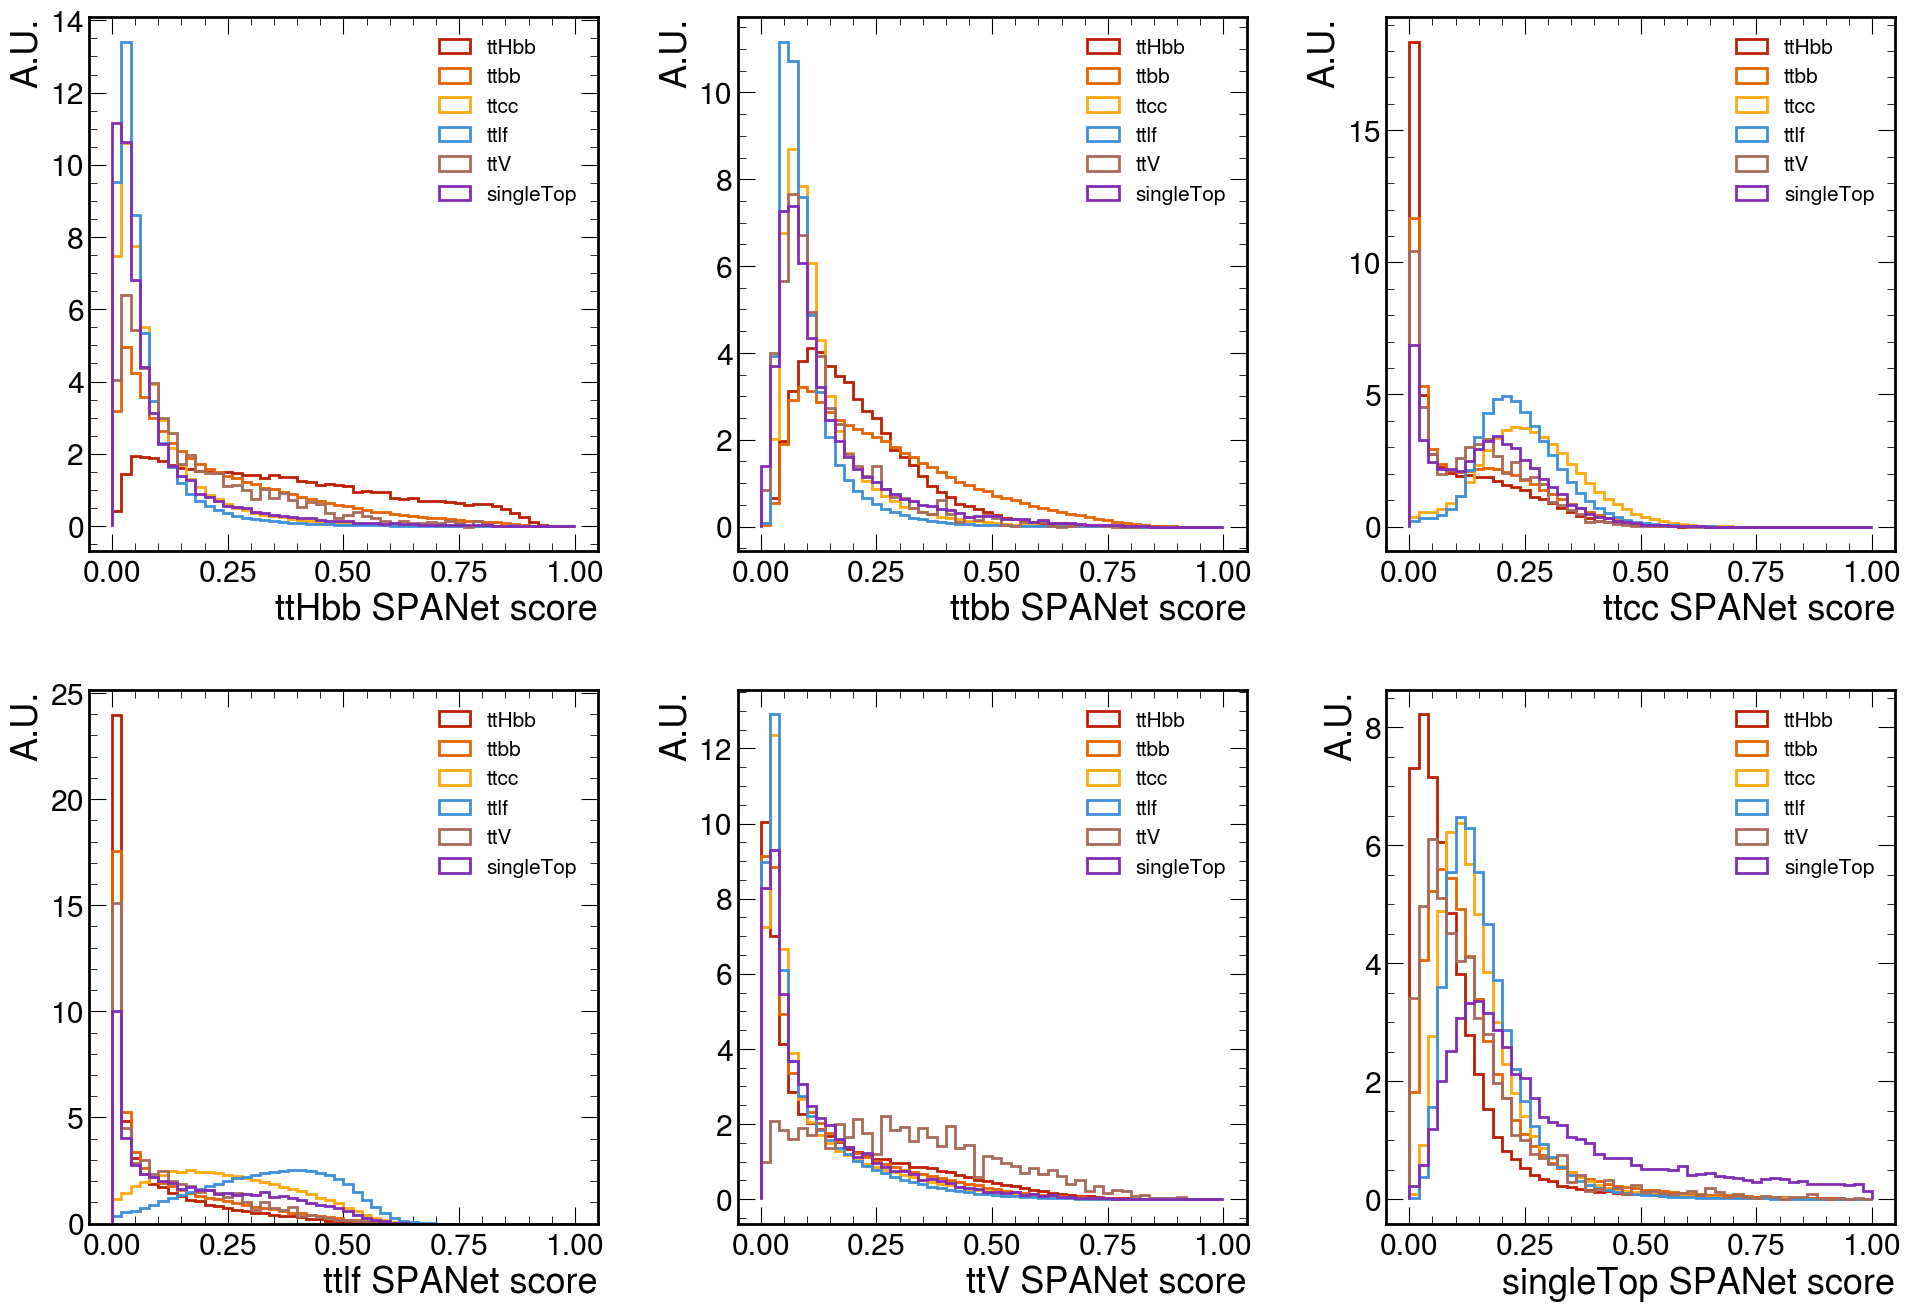

In [11]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, density=True) # mask by sample

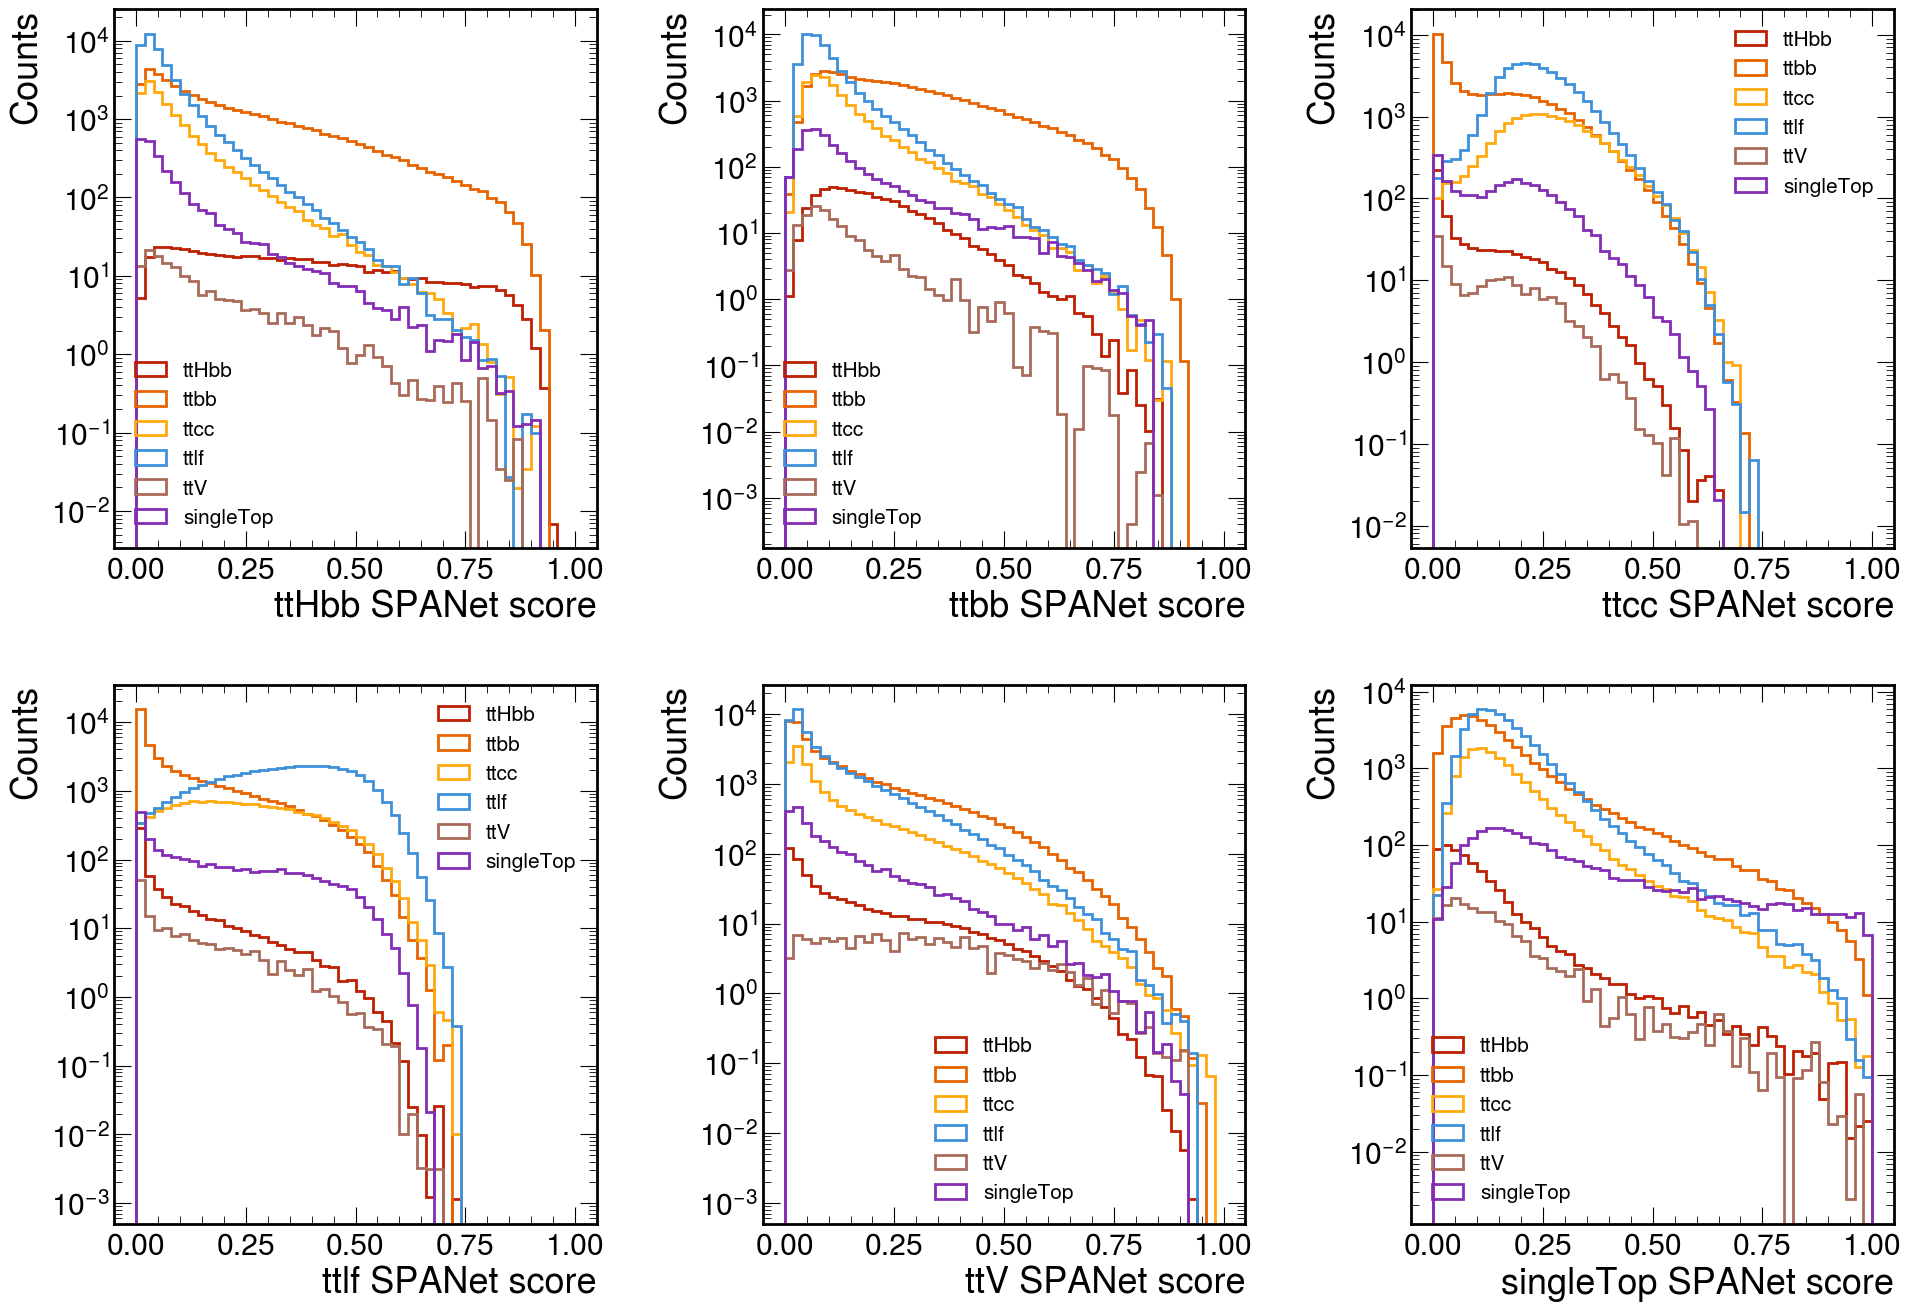

In [12]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, log=True) # mask by sample

## Correlation between scores
The scores of the signal and the other ttbar background should be correlated. Plots to show the correlation between the scores 

In [13]:
def plot_correlation(score1, score2, label1, label2, ax, weights=None):
    #ax.hist2d(score1, score2, bins=(10,10), range=((0,1),(0,1)), norm=matplotlib.colors.LogNorm())
    _,_,_,I = ax.hist2d(score1, score2, bins=(10,10), range=((0,1),(0,1)), cmin=1e-5, weights=weights)
    ax.set_xlabel(label1)
    ax.set_ylabel(label2)
    plt.colorbar(I, ax=ax)

def plot_correlations(pred_labels, mask=None, weights=None):
    fig, axes = plt.subplots(4, 4, figsize=[12,10])
    corr_labels = ["ttHbb", "ttbb", "ttcc", "ttlf"]
    for i, label1 in enumerate(corr_labels):
        for j, label2 in enumerate(corr_labels):
            ax = axes[j][i]
            if i > j:
                ax.axis('off')
                continue
            pred_label1 = pred_labels[label1]
            pred_label2 = pred_labels[label2]
            if type(mask) != None:
                weights_masked = weights[mask]
                pred_label1 = pred_label1[mask]
                pred_label2 = pred_label2[mask]          
            plot_correlation(pred_label1, pred_label2, label1, label2, ax, weights=weights_masked)
           
    fig.tight_layout(pad=0.5)

In [14]:
# creating masks by sample
is_tthbb = true_labels["ttHbb"]
is_ttbb  = true_labels["ttbb"]
is_ttcc  = true_labels["ttcc"]
is_ttlf  = true_labels["ttlf"]

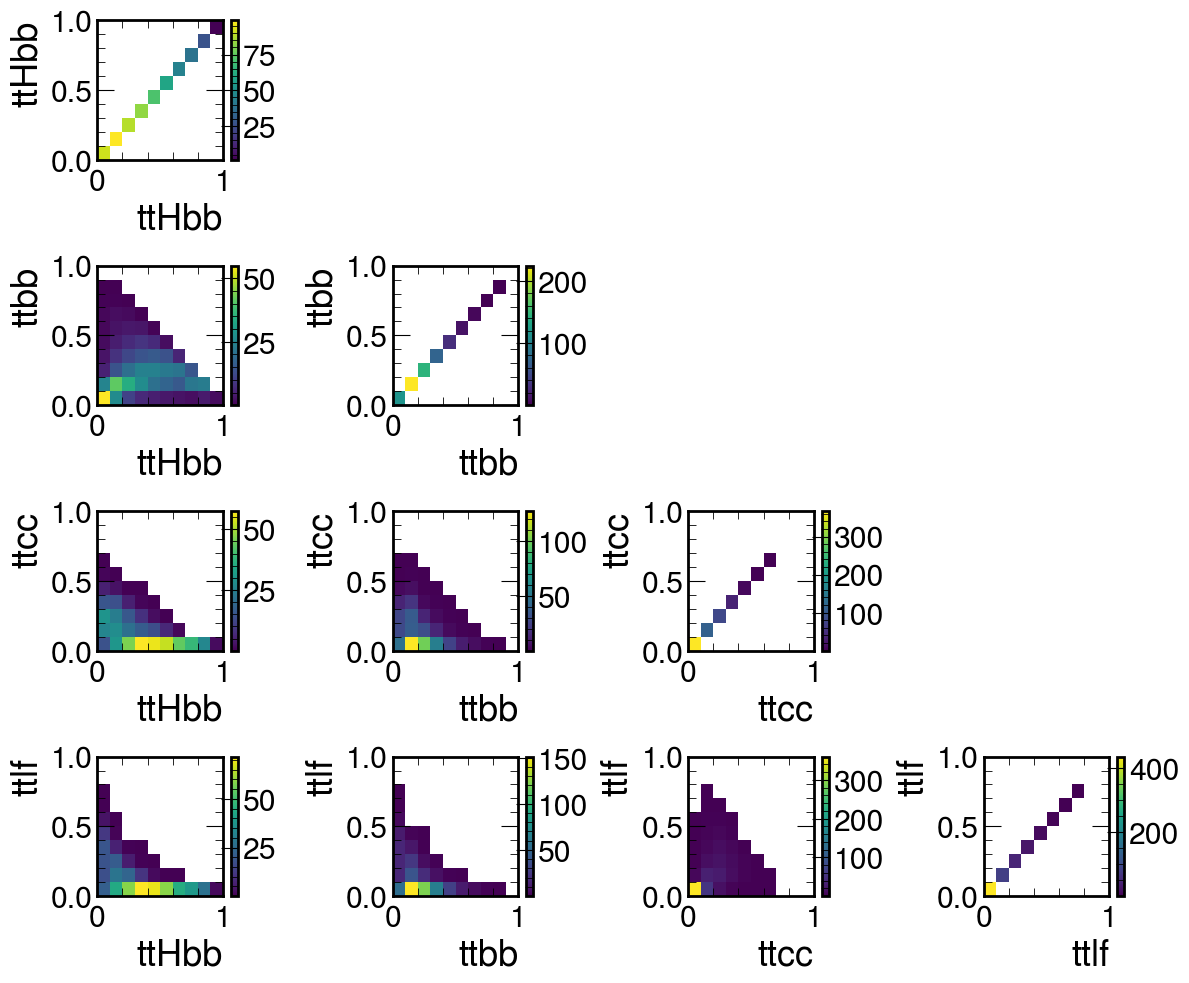

In [15]:
plot_correlations(pred_labels, mask=is_tthbb, weights=weights)

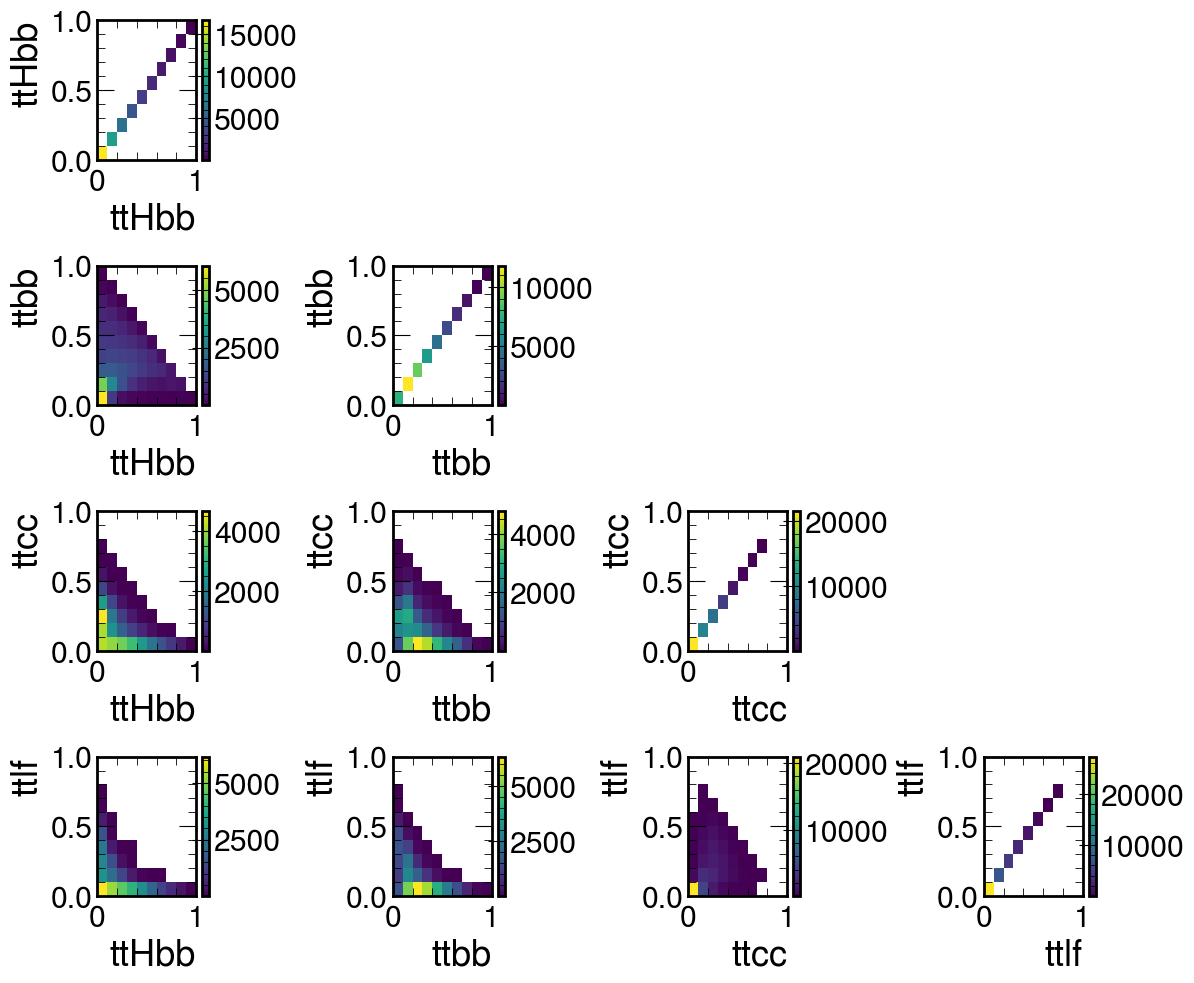

In [16]:
plot_correlations(pred_labels, mask=is_ttbb, weights=weights)

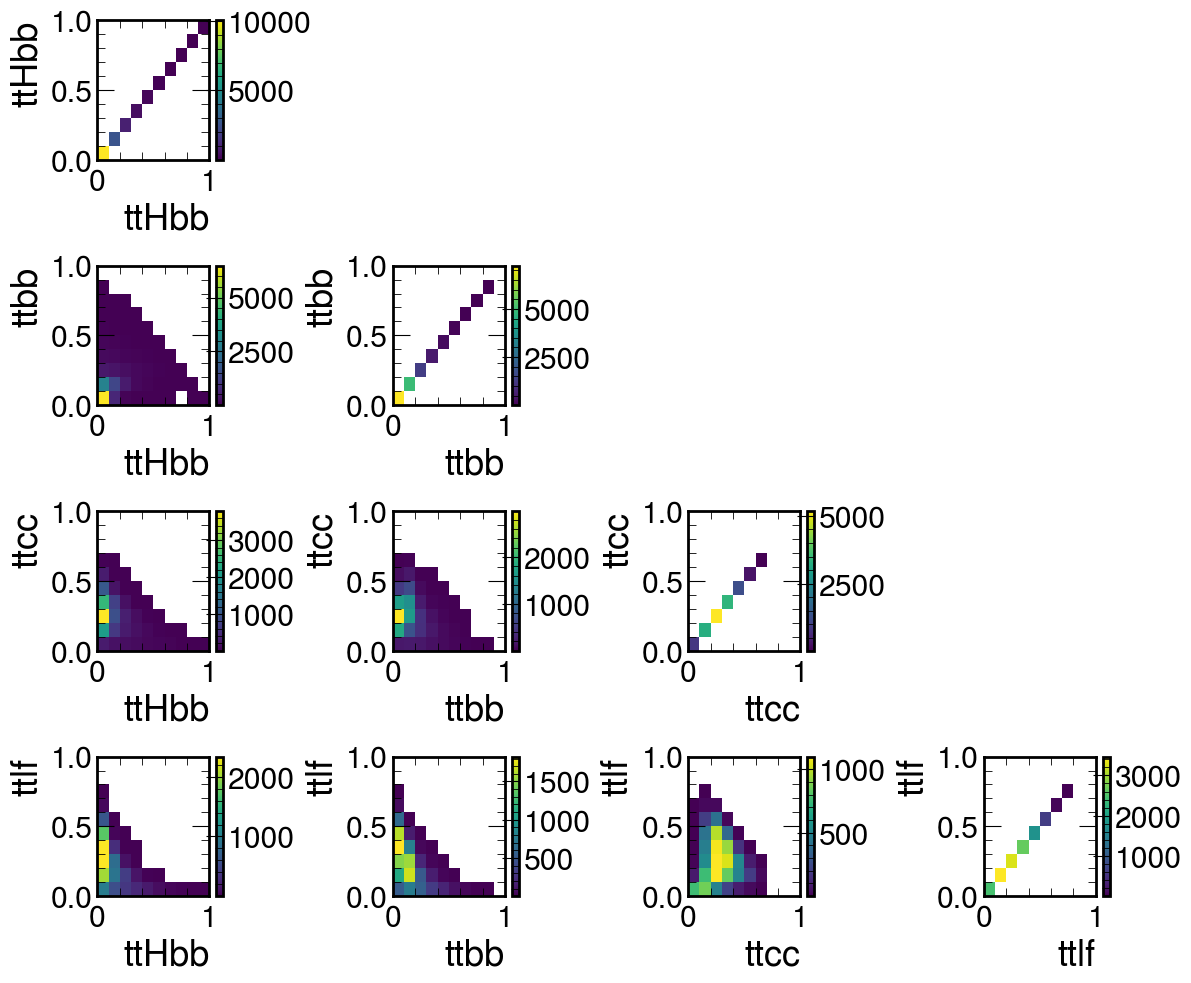

In [17]:
plot_correlations(pred_labels, mask=is_ttcc, weights=weights)

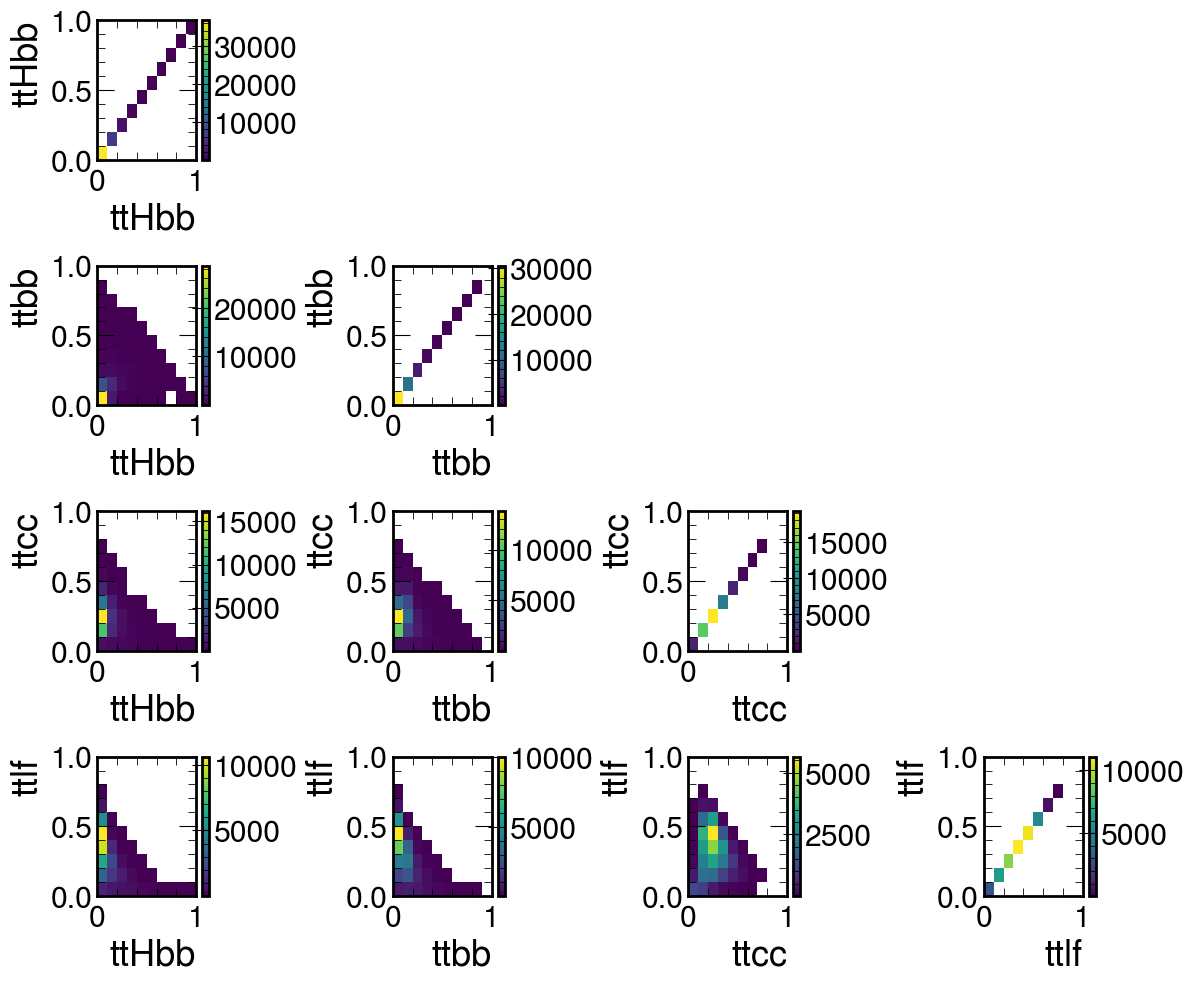

In [18]:
plot_correlations(pred_labels, mask=is_ttlf, weights=weights)

## LF score cut optimization

In [19]:
low_score = 0.10
high_score = 0.75
score_thr = np.round(np.arange(low_score, high_score, 0.02), 2)

In [20]:
masks = {}
for label in labels:
    masks[label] = {}
    for thr in score_thr:
        masks[label][thr] = (pred_labels[label] > thr) & true_labels[label] # added mask_per_sample

In [21]:
# not weighted and weighted purity
purity_ttlf = {}
purity_ttlf_weighted = {}

for thr in score_thr:
    num   = sum(masks["ttlf"][thr])
    num_w = sum(masks["ttlf"][thr]*weights)
    den = 0
    den_w = 0
    for label in labels:
        den   += np.sum(masks[label][thr]) # all selected events       
        den_w += np.sum(masks[label][thr]*weights)
    
    purity_ttlf[thr] = num / den if den > 0 else 0.0
    purity_ttlf_weighted[thr] = num_w / den_w if den_w > 0 else 0.0

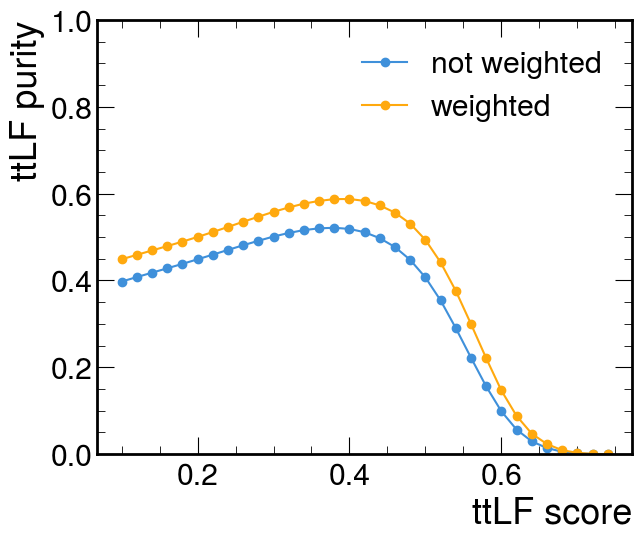

In [22]:
ttlf_score    = np.array(sorted(purity_ttlf.keys()))
purities_lf   = np.array([purity_ttlf[thr] for thr in ttlf_score])
purities_lf_w = np.array([purity_ttlf_weighted[thr] for thr in ttlf_score])

fig, ax = plt.subplots(figsize=[7,6])
ax.plot(ttlf_score, purities_lf,marker='o', linestyle='-', color=CMAP_10[0], label="not weighted")
ax.plot(ttlf_score, purities_lf_w,marker='o', linestyle='-', color=CMAP_10[1], label="weighted")
ax.set_xlabel("ttLF score")
ax.set_ylabel("ttLF purity")
ax.legend()
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

We get the optimal cut by maximizing the ttLF purity to define the ttLF control region

In [23]:
best_idx = np.argmax(purities_lf_w)
best_thr = ttlf_score[best_idx]
best_purity = purities_lf_w[best_idx]
best_thr, best_purity

(np.float64(0.4), np.float32(0.5876454))

The best cut of the score for the ttLF CR is 

$ttLF\_score > 0.4$

# Quantile transformation of ttHbb spanet score

In [24]:
from sklearn.preprocessing import QuantileTransformer
from copy import deepcopy
import numpy as np
from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin

In [25]:
is_tthbb = true_labels["ttHbb"]
score = pred_labels["ttHbb"][is_tthbb]
score

array([0.43316707, 0.5685145 , 0.12717423, ..., 0.82052726, 0.3726433 ,
       0.06976037], dtype=float32)

In [26]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

In [27]:
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
X = score
transformer.fit(X, sample_weight=weights[is_tthbb])
transformed_X = transformer.transform(X)

In [28]:
transformed_X.shape

(314589,)

In [29]:
qt = QuantileTransformer(n_quantiles=10000, random_state=0, subsample=10**6)
qt

QuantileTransformer(n_quantiles=10000, random_state=0, subsample=1000000)

In [30]:
qt_signal = qt.fit(score.reshape(-1,1))
# Update the tthbb score
pred_labels_new = deepcopy(pred_labels)
#pred_labels_new["tthbb"] = np.ravel(qt_signal.transform(pred_labels["tthbb"].reshape(-1,1)))
pred_labels_new["ttHbb"] = np.ravel(transformer.transform(pred_labels["ttHbb"].reshape(-1,1)))
qt_signal

QuantileTransformer(n_quantiles=10000, random_state=0, subsample=1000000)

In [31]:
pred_labels_new

{'ttHbb': array([0.06316083, 0.01813172, 0.00072576, ..., 0.02696434, 0.06436438,
        0.00878958]),
 'ttbb': array([0.12848273, 0.5959306 , 0.05886112, ..., 0.10505158, 0.0705637 ,
        0.05636366], dtype=float32),
 'ttcc': array([0.37235773, 0.06229166, 0.3411126 , ..., 0.2518409 , 0.18817295,
        0.25203848], dtype=float32),
 'ttlf': array([0.24045295, 0.01129344, 0.35925776, ..., 0.29390523, 0.39142853,
        0.5187441 ], dtype=float32),
 'ttV': array([0.09293244, 0.127193  , 0.09505381, ..., 0.11821292, 0.10397193,
        0.02014323], dtype=float32),
 'singleTop': array([0.11210819, 0.17558089, 0.13781819, ..., 0.19769563, 0.19148248,
        0.13240997], dtype=float32)}

Text(0, 1, 'Counts')

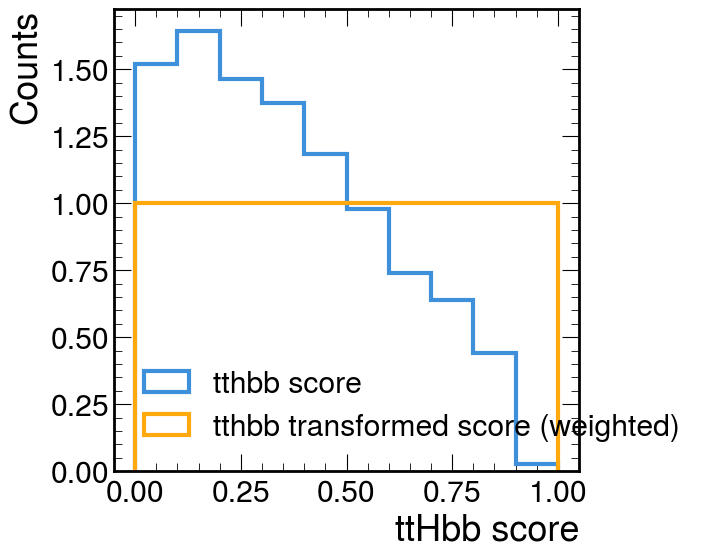

In [32]:
fig, ax = plt.subplots(1,1, figsize=[6,6])
ax.hist(score, weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", color=CMAP_10[0], linewidth=3, label="tthbb score", density=True)
#ax.hist(qt_signal.transform(score.reshape(-1,1)), bins=10, range=(0,1), histtype="step", linewidth=3, label="tthbb transformed score", density=True)
ax.hist(transformed_X, weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", color=CMAP_10[1], linewidth=3, label="tthbb transformed score (weighted)", density=True)
ax.legend(loc='best');
ax.set_xlabel("ttHbb score")
ax.set_ylabel("Counts")

Plot the scores with the transformed ttHbb score after quantile regression

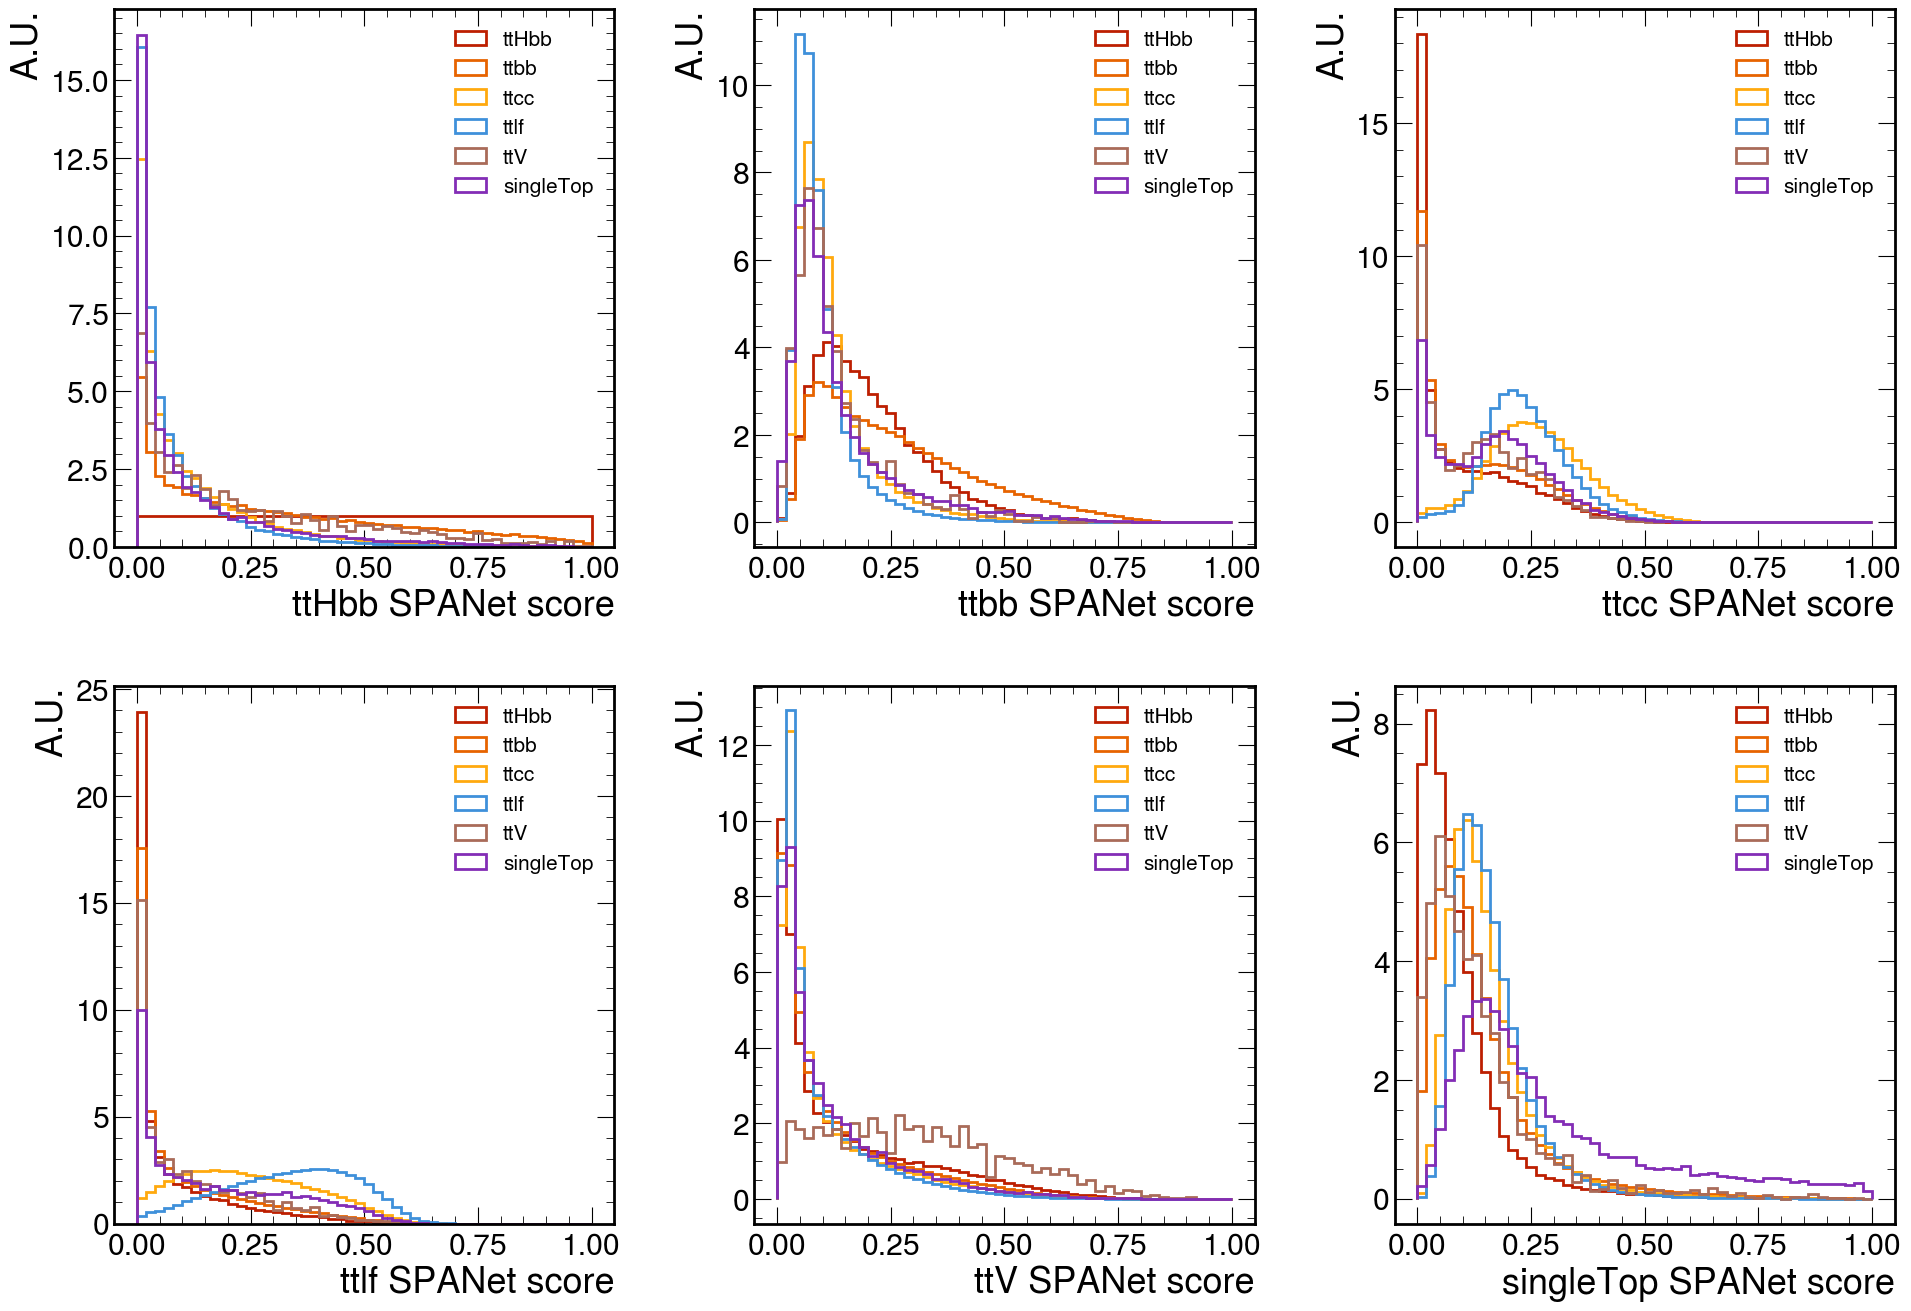

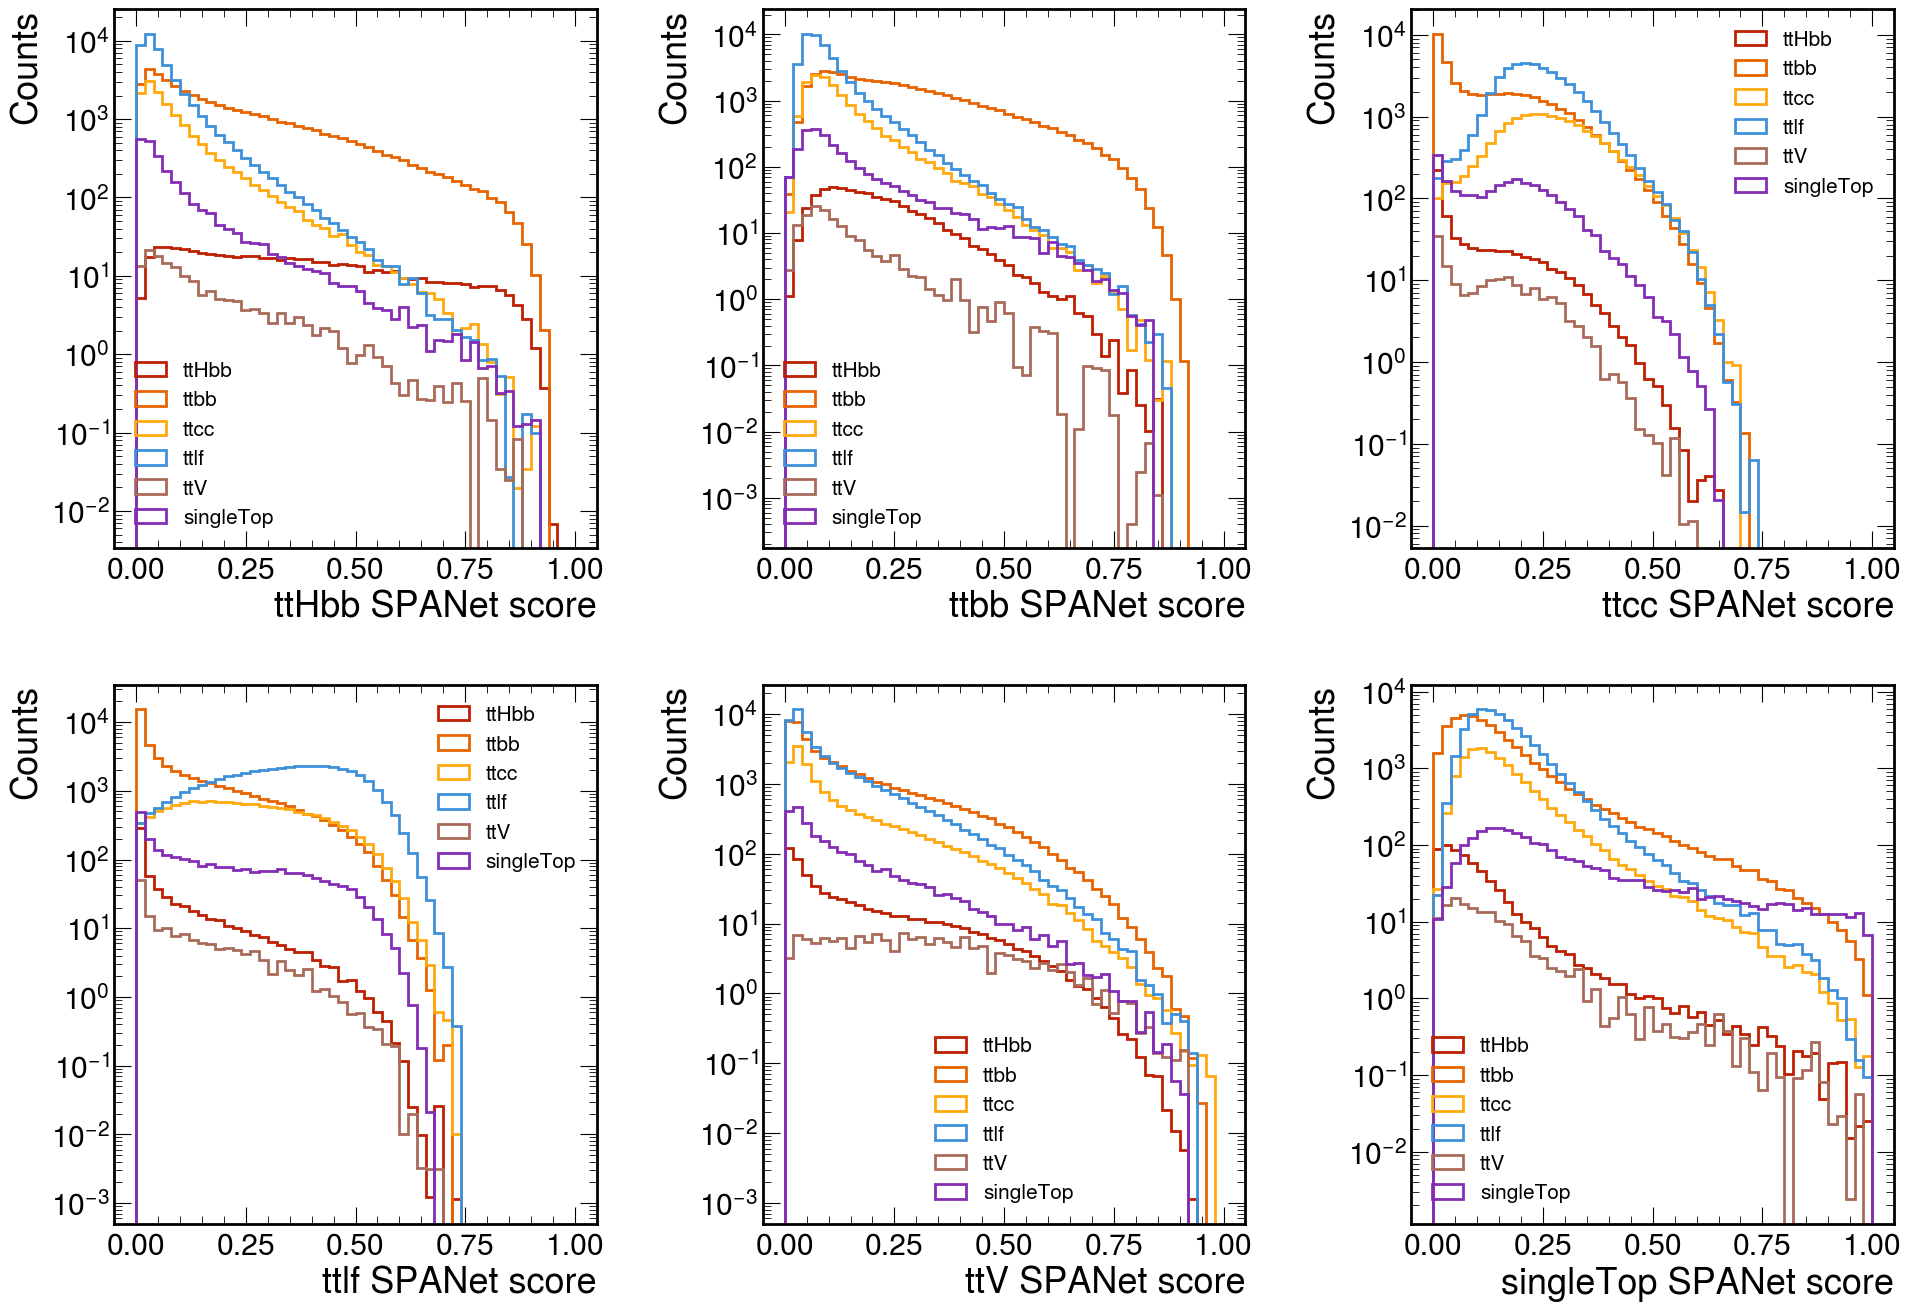

In [33]:
plot_scores(true_labels, pred_labels_new, weights=weights, plot_dir=out_folder, density=True) # mask by sample
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, log=True) # mask by sample

In [34]:
# redefine mask after the ttHbb quantile transformationm
masks_new = {}
scores = ["ttHbb", "ttbb","ttcc","ttlf","ttV","singleTop"]
for score in scores:
    masks_new[score] = {}
    for sample in labels:
        masks_new[score][sample] = {}
        for thr in score_thr:
           masks_new[score][sample][thr] = (pred_labels_new[score] > thr) & true_labels[sample] # added mask_per_sample

In [35]:
masks_new

{'ttHbb': {'ttHbb': {np.float64(0.1): array([False, False, False, ..., False, False, False]),
   np.float64(0.12): array([False, False, False, ..., False, False, False]),
   np.float64(0.14): array([False, False, False, ..., False, False, False]),
   np.float64(0.16): array([False, False, False, ..., False, False, False]),
   np.float64(0.18): array([False, False, False, ..., False, False, False]),
   np.float64(0.2): array([False, False, False, ..., False, False, False]),
   np.float64(0.22): array([False, False, False, ..., False, False, False]),
   np.float64(0.24): array([False, False, False, ..., False, False, False]),
   np.float64(0.26): array([False, False, False, ..., False, False, False]),
   np.float64(0.28): array([False, False, False, ..., False, False, False]),
   np.float64(0.3): array([False, False, False, ..., False, False, False]),
   np.float64(0.32): array([False, False, False, ..., False, False, False]),
   np.float64(0.34): array([False, False, False, ..., False, 

## ttLF control region

In [36]:
# only weighted purity for all samples in all scores for different scores cuts
purity = {}
for score in scores:
    purity[score] = {}
    for sample in labels:
        purity[score][sample] = {}
        for thr in score_thr:
            num = sum(masks_new[score][sample][thr]*weights)
            den = sum(np.sum(masks_new[score][s][thr] * weights) for s in labels)
            purity[score][sample][thr] = num / den if den > 0 else 0.0

In [37]:
labels_to_plot = {
    "ttHbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4
}

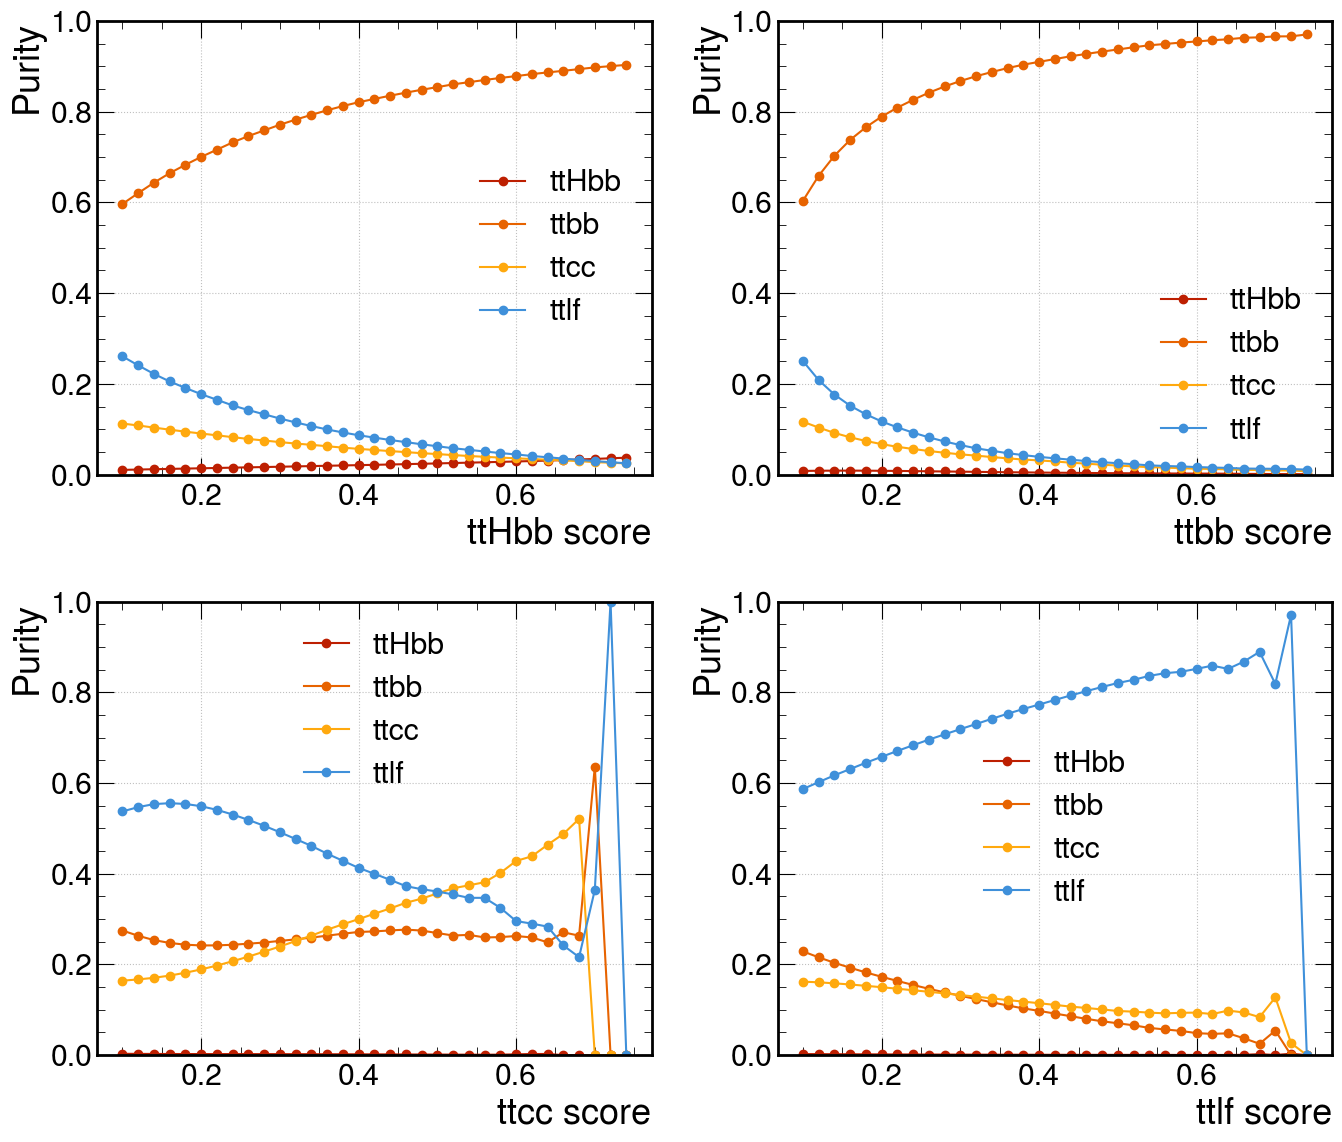

In [38]:
thr_vals = np.array(score_thr)

scores_to_plot = list(labels_to_plot.keys())   # or your score list
n_scores = len(scores_to_plot)

fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([purity[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Purity")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

We observe that when the ttLF has very high purity the other sample with high purity is ttC, which makes sense. It is easier indeed to mistake ttC for ttLF rather than ttB.
However, it is not clear just by looking at the plot which cut to choose for the LF CR so we also check the efficiency which is defined as

$Efficiency = \frac{sample(in\_cut)}{sample(in\_cut)+sample(out\_cut)}$

The denominator therefore is simply obtained by a mask per sample that counts the sum of the events in and out of the cut.

In [39]:
efficiency = {}
for score in scores:
    efficiency[score] = {}
    for sample in labels:
        efficiency[score][sample] = {}
        for thr in score_thr:
            num = sum(masks_new[score][sample][thr]*weights)
            den = np.sum(true_labels[sample] * weights)
            efficiency[score][sample][thr] = num / den if den > 0 else 0.0

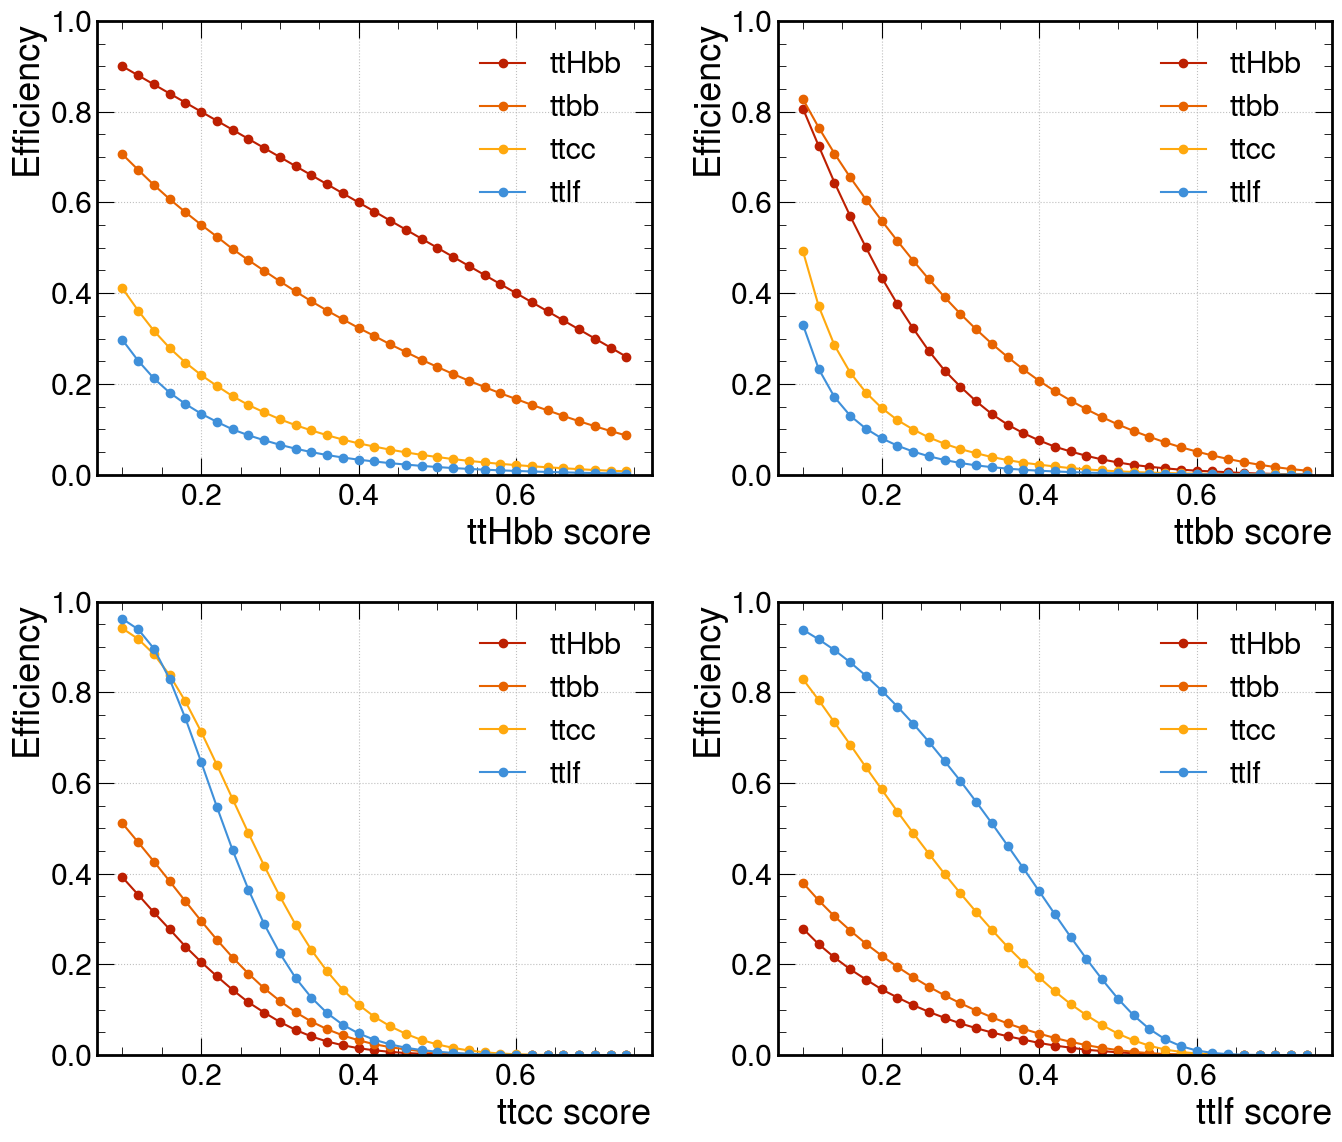

In [40]:
fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([efficiency[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

with 0.4 cut we would loose less than 10% of the signal

## Figures of merit
**1.** Take the product of the purity and efficiency as a figure of merit to find a compromise for the optimal score to cut for the ttLF CR

In [41]:
eff_purity = {}

for score in scores:
    eff_purity[score] = {}
    for sample in labels:
        eff_purity[score][sample] = {}
        for thr in score_thr:
            eff_purity[score][sample][thr] = (efficiency[score][sample][thr]*purity[score][sample][thr])

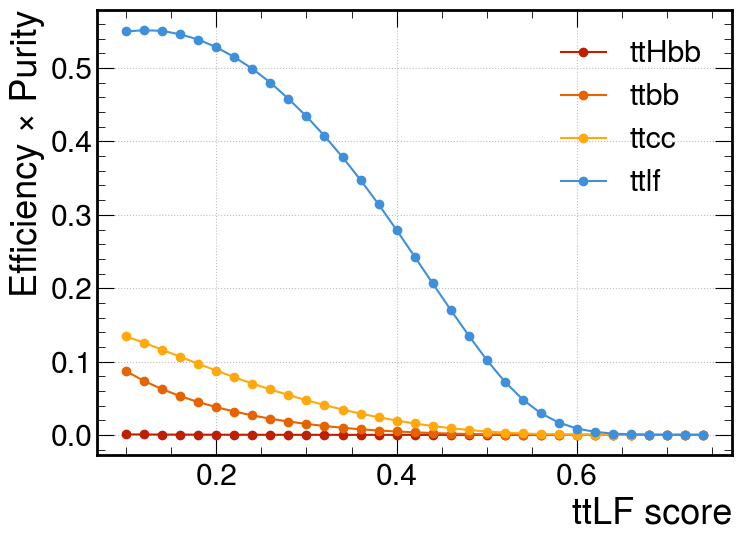

In [42]:
fig, ax = plt.subplots(figsize=(8, 6))
score = "ttlf"
for sample in labels_to_plot:
    eff_purity_values = np.array([eff_purity[score][sample][thr] for thr in thr_vals])
    # plot using your color mapping dict
    ax.plot(thr_vals, eff_purity_values,marker='o',linestyle='-',color=colors[sample],label=sample)

ax.set_xlabel("ttLF score")
ax.set_ylabel("Efficiency × Purity")
#ax.set_ylim(0, 1)
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

**2.** Signal significance. In this case the "signal" is the ttLF and all the rest is background

In [43]:
signal_sample = "ttlf"
score = "ttlf"
significance = {}
for thr in score_thr:
    score_mask = pred_labels_new[score] > thr
    S = np.sum(weights[score_mask & true_labels[signal_sample]])
    B = np.sum(weights[score_mask & ~true_labels[signal_sample]])
    significance[thr] = S / np.sqrt(S + B) if (S + B) > 0 else 0.0

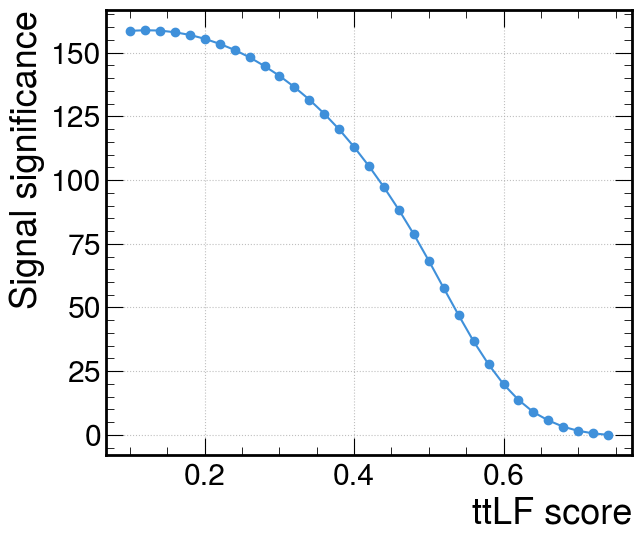

In [44]:
thr_vals = np.array(list(significance.keys()))
sig_vals = np.array(list(significance.values()))

plt.figure(figsize=(7,6))
plt.plot(thr_vals, sig_vals, marker='o', color=colors[signal_sample], linestyle='-')
plt.xlabel("ttLF score")
plt.ylabel("Signal significance")
plt.grid(True)
plt.tight_layout()
plt.show()

**3.** We can optimize Purity(ttLF) * (1 - Efficiency(ttHbb) ) to maximize the purity of the background and the significance of the signal

In [45]:
purityLF_effttHbb = {}
signal_sample = "ttHbb"
score = "ttlf"

for thr in score_thr:
    purityLF_effttHbb[thr] = (purity[score]["ttlf"][thr]*(1-efficiency[score][signal_sample][thr]))

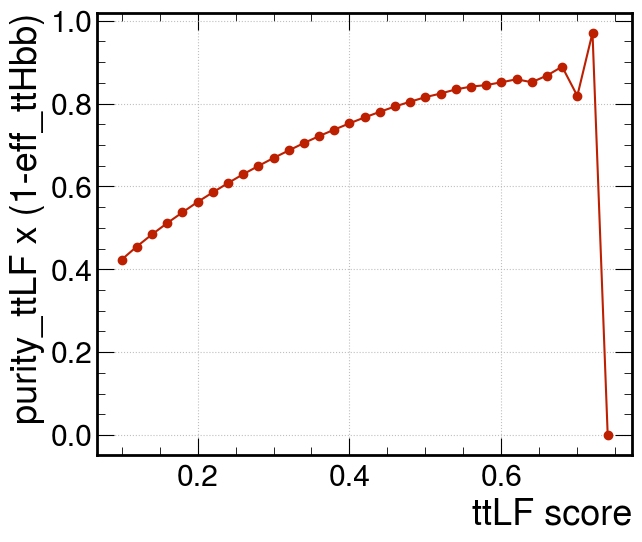

In [46]:
sig_vals = np.array(list(purityLF_effttHbb.values()))

plt.figure(figsize=(7,6))
plt.plot(thr_vals, sig_vals, marker='o', color=colors[signal_sample], linestyle='-')
plt.xlabel("ttLF score")
plt.ylabel("purity_ttLF x (1-eff_ttHbb)")
plt.grid(True)
plt.tight_layout()
plt.show()

**4.** purity(ttlf) * (1 - purity (ttcc) - purity (ttbb) - purity (tthbb) ) 

In [47]:
score = "ttlf"
FoM = {}
for thr in score_thr:
    FoM[thr] = (purity[score]["ttlf"][thr]*(1-(purity[score]["ttHbb"][thr]+purity[score]["ttbb"][thr]+purity[score]["ttcc"][thr])))

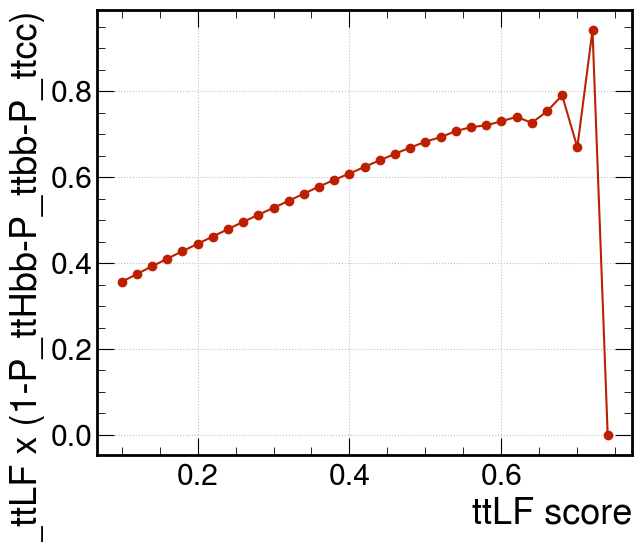

In [48]:
fom = np.array(list(FoM.values()))

plt.figure(figsize=(7,6))
plt.plot(thr_vals, fom, marker='o', color=colors[signal_sample], linestyle='-')
plt.xlabel("ttLF score")
plt.ylabel("P_ttLF x (1-P_ttHbb-P_ttbb-P_ttcc)")
plt.grid(True)
plt.tight_layout()
plt.show()

## ttB control region
From the purity plots it looks like we can already make a cut for the ttbb score without loosing too much efficiency on the other ttbar backgrounds. We can cut on the ttbb score to define the CR around 0.4-0.5

## ttC control region

Define a ttLF region with a cut on the ttLF score (ttLF_score > ttlf_high). Then we want to discard a middle region in which (ttlf_low < ttLF_score < ttlf_high). The ttlf_low defines a region that is not enriched in ttLF but is enriched in ttHbb signal instead. We have a look at the ttC score in the region where (ttLF_score < ttlf_high & ttLF_score < ttlf_low)

In [49]:
ttlf_low = 0.2
ttlf_high = 0.5
tthbb_cut = 0.4 # < 40% efficiency of the signal (transformed score)

In [50]:
# redefine mask after the ttHbb quantile transformation for the ttC region
masks_ttc = {}
mask_ttlf_cr = (pred_labels_new["ttlf"] < ttlf_low)
#mask_tthbb = (pred_labels_new["ttHbb"] < tthbb_cut)
scores = ["ttHbb", "ttbb","ttcc","ttlf","ttV","singleTop"]
for score in scores:
    masks_ttc[score] = {}
    for sample in labels:
        masks_ttc[score][sample] = {}
        for thr in score_thr:
            masks_ttc[score][sample][thr] = (pred_labels_new[score] > thr) & true_labels[sample] & mask_ttlf_cr #& mask_tthbb 
            # added mask_per_sample, ttlf CR exclusion requiring < 40% of the signal

In [51]:
# only weighted purity and efficiency for all samples in all scores for different scores cuts
purity = {}
efficiency = {}

for score in scores:
    purity[score] = {}
    efficiency[score] = {}
    for sample in labels:
        purity[score][sample] = {}
        efficiency[score][sample] = {}
        for thr in score_thr:
            num = sum(masks_ttc[score][sample][thr]*weights)
            den1 = sum(np.sum(masks_ttc[score][s][thr] * weights) for s in labels)
            den2 = np.sum(true_labels[sample] * weights)
            purity[score][sample][thr] = num / den1 if den1 > 0 else 0.0
            efficiency[score][sample][thr] = num / den2 if den2 > 0 else 0.0

In [52]:
labels_to_plot = {
    "ttHbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4
}

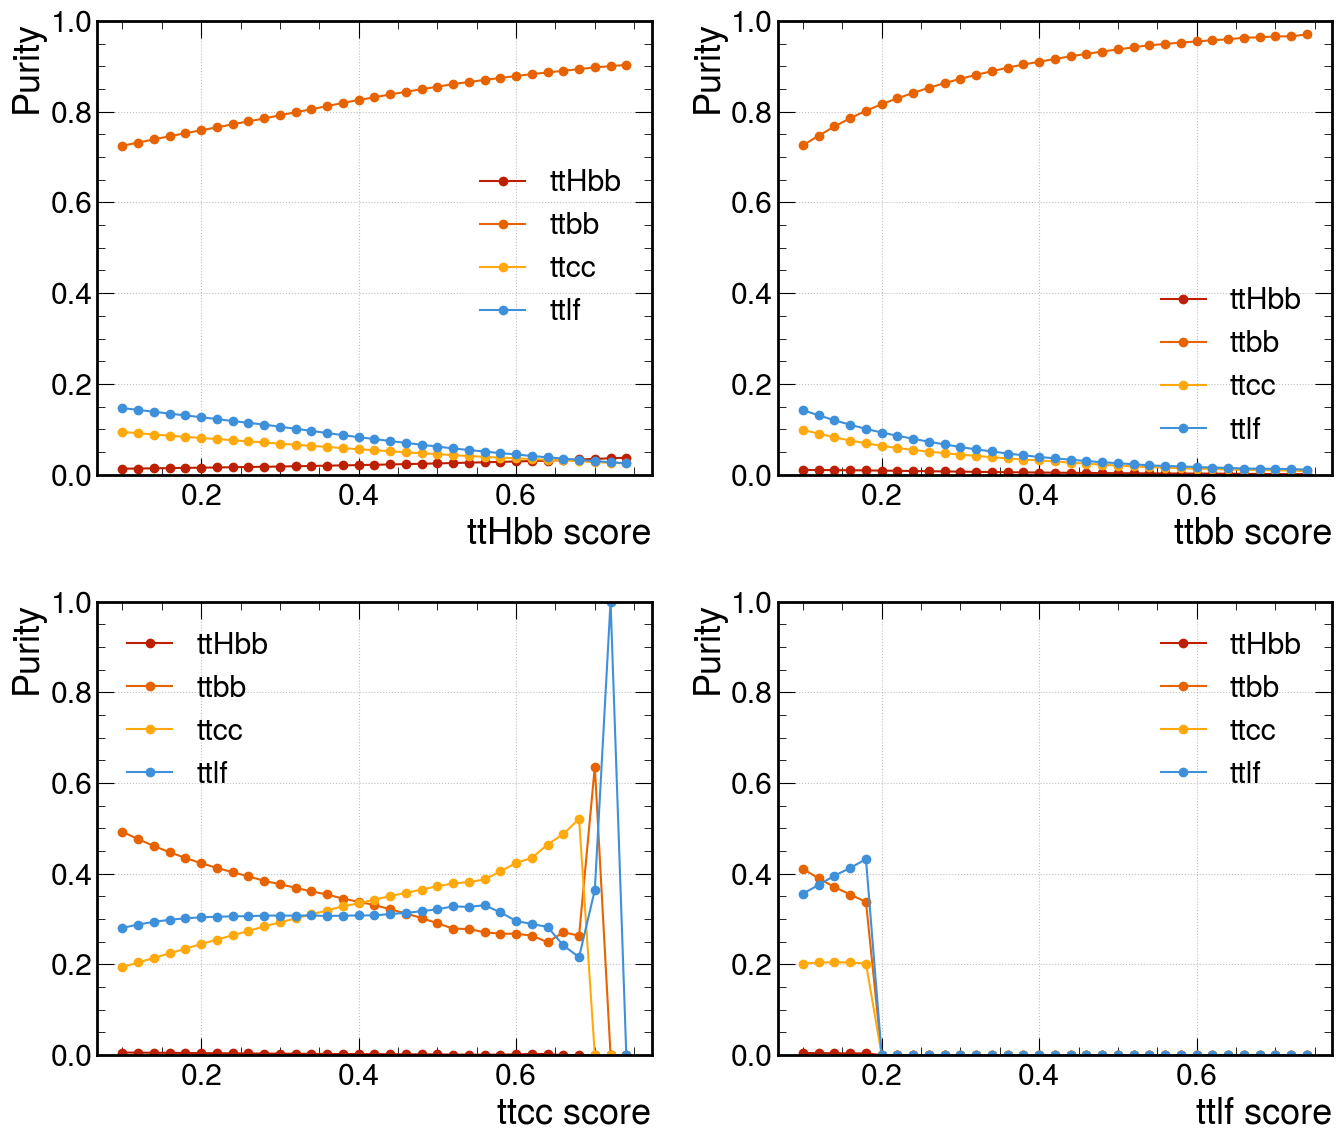

In [53]:
thr_vals = np.array(score_thr)

scores_to_plot = list(labels_to_plot.keys())   # or your score list
n_scores = len(scores_to_plot)

fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([purity[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Purity")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

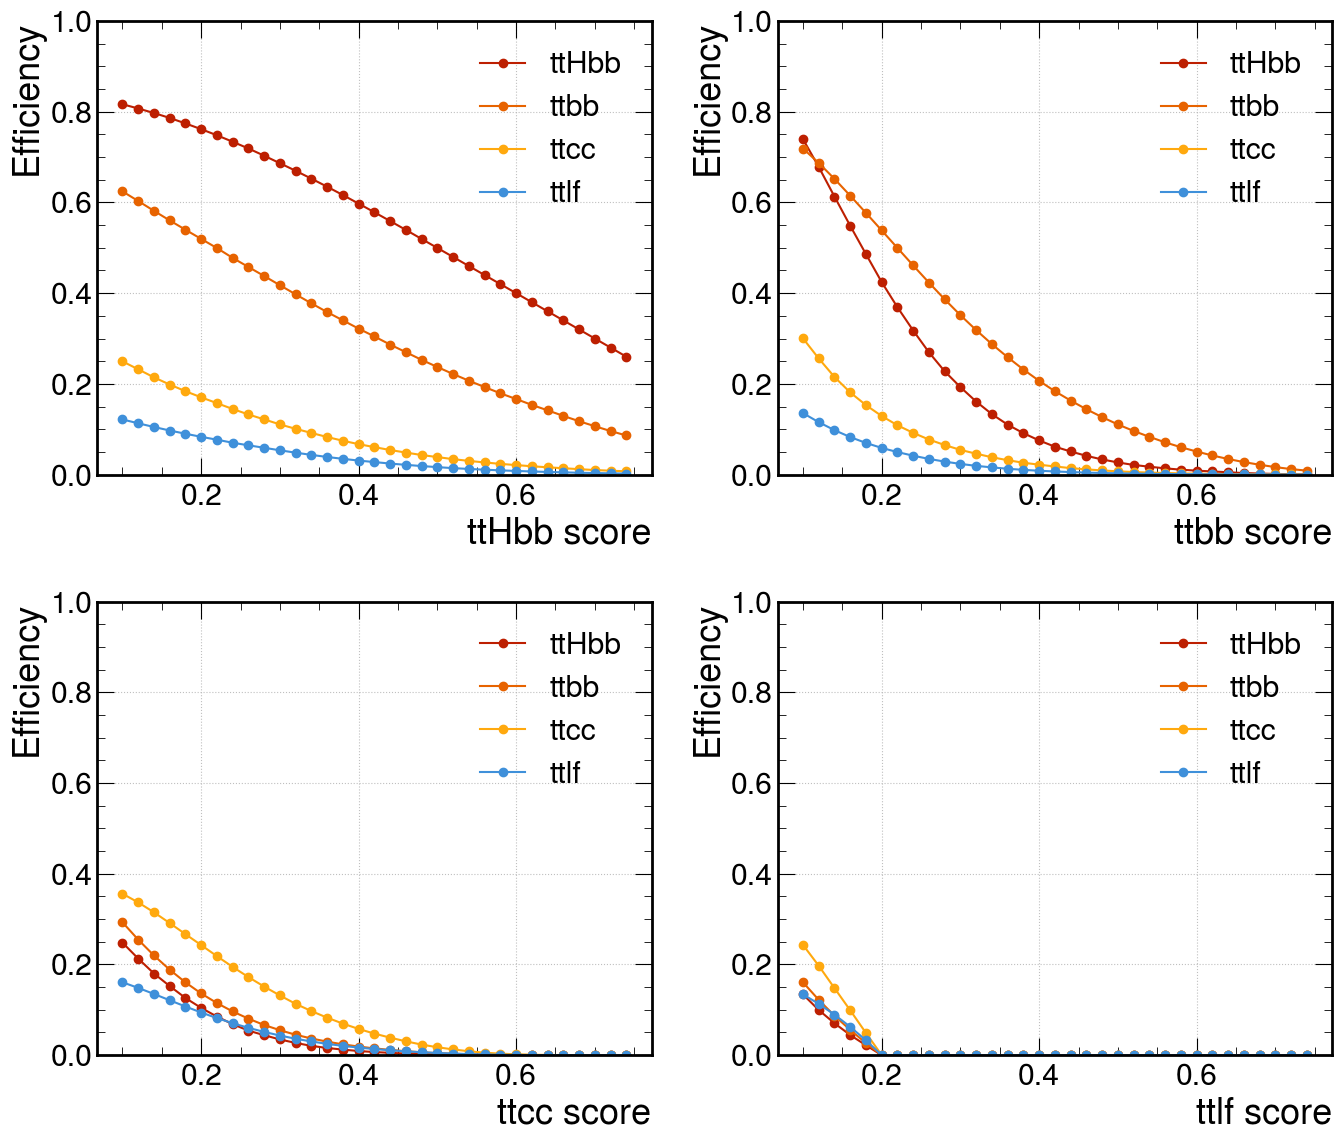

In [54]:
fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([efficiency[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [55]:
score_thr_tthbb = np.round(np.arange(0.1, 1, 0.02), 2)
thr_tthbb = np.array(score_thr_tthbb)
# redefine mask after the ttHbb quantile transformation for the ttC region
masks_ttc = {}
mask_ttlf_cr = (pred_labels_new["ttlf"] < ttlf_low)
masks_ttc["ttHbb"] = {}
for sample in labels:
    masks_ttc["ttHbb"][sample] = {}
    for thr in score_thr_tthbb:
       masks_ttc["ttHbb"][sample][thr] = (pred_labels_new["ttHbb"] > thr) & true_labels[sample] & mask_ttlf_cr #& mask_tthbb 

In [56]:
for sample in labels:
    purity["ttHbb"][sample] = {}
    efficiency["ttHbb"][sample] = {}
    for thr in score_thr_tthbb:
        num = sum(masks_ttc["ttHbb"][sample][thr]*weights)
        den1 = sum(np.sum(masks_ttc["ttHbb"][s][thr] * weights) for s in labels)
        den2 = np.sum(true_labels[sample] * weights)
        purity["ttHbb"][sample][thr] = num / den1 if den1 > 0 else 0.0
        efficiency["ttHbb"][sample][thr] = num / den2 if den2 > 0 else 0.0

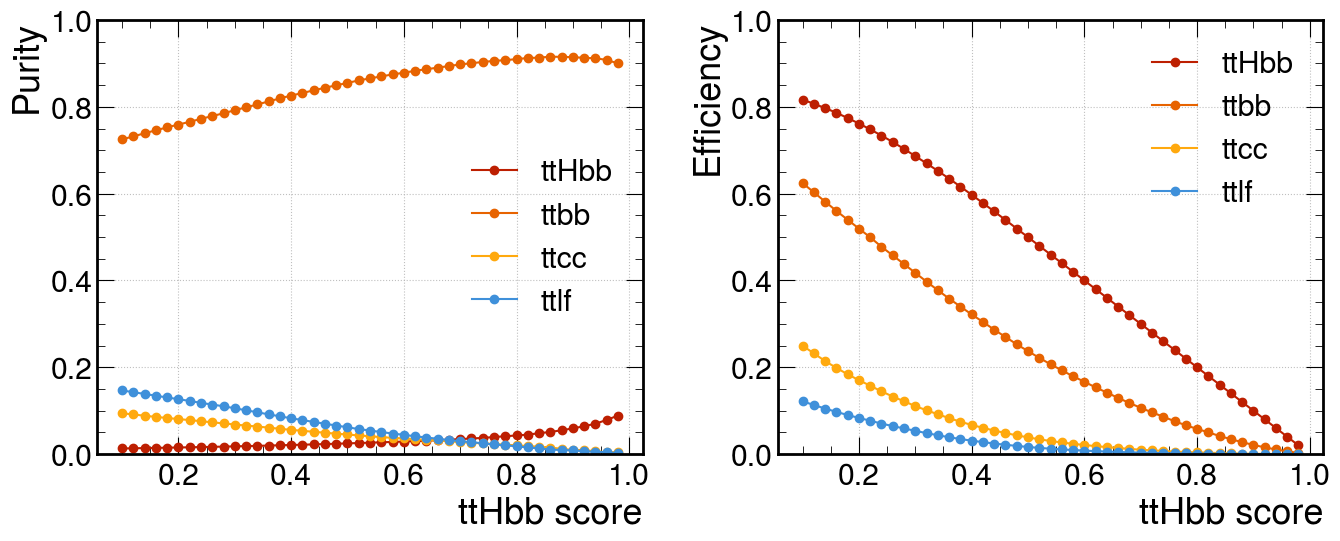

In [57]:
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(14, 6))
for sample in labels_to_plot.keys():
    pur_vals = np.array([purity["ttHbb"][sample][thr] for thr in thr_tthbb])
    eff_vals = np.array([efficiency["ttHbb"][sample][thr] for thr in thr_tthbb])
    ax1.plot(thr_tthbb,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)
    ax2.plot(thr_tthbb,eff_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

ax1.set_xlabel("ttHbb score")
ax2.set_xlabel("ttHbb score")
ax1.set_ylabel("Purity")
ax2.set_ylabel("Efficiency")
ax1.set_ylim(0, 1)
ax1.grid(True)
ax1.legend()
ax2.set_ylim(0, 1)
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

From the ttHbb score we can decide to cut $ttHbb\_score < 0.5$ for the ttC control region and $ttHbb\_score > 0.8$ for the ttHbb SR.

From the ttcc score in the purity plots it looks like we can cut the score around 0.5-0.6 where the ttC is dominant with respect to the other ttbar backgrounds  but we first have a look at the distribution where only the ttHbb cut is applied after inverting the ttlf control  region

In [58]:
# redefine mask after the ttHbb quantile transformation for the ttC region
masks_ttc = {}
tthbb_cut = 0.5
mask_ttlf_cr = (pred_labels_new["ttlf"] < ttlf_low)
mask_tthbb = (pred_labels_new["ttHbb"] < tthbb_cut)
scores = ["ttHbb", "ttbb","ttcc","ttlf","ttV","singleTop"]
for score in scores:
    masks_ttc[score] = {}
    for sample in labels:
        masks_ttc[score][sample] = {}
        for thr in score_thr:
            masks_ttc[score][sample][thr] = (pred_labels_new[score] > thr) & true_labels[sample] & mask_ttlf_cr & mask_tthbb 
            # added mask_per_sample, ttlf CR exclusion requiring < 50% of the signal

In [59]:
# only weighted purity and efficiency for all samples in all scores for different scores cuts
purity = {}
efficiency = {}

for score in scores:
    purity[score] = {}
    efficiency[score] = {}
    for sample in labels:
        purity[score][sample] = {}
        efficiency[score][sample] = {}
        for thr in score_thr:
            num = sum(masks_ttc[score][sample][thr]*weights)
            den1 = sum(np.sum(masks_ttc[score][s][thr] * weights) for s in labels)
            den2 = np.sum(true_labels[sample] * weights)
            purity[score][sample][thr] = num / den1 if den1 > 0 else 0.0
            efficiency[score][sample][thr] = num / den2 if den2 > 0 else 0.0

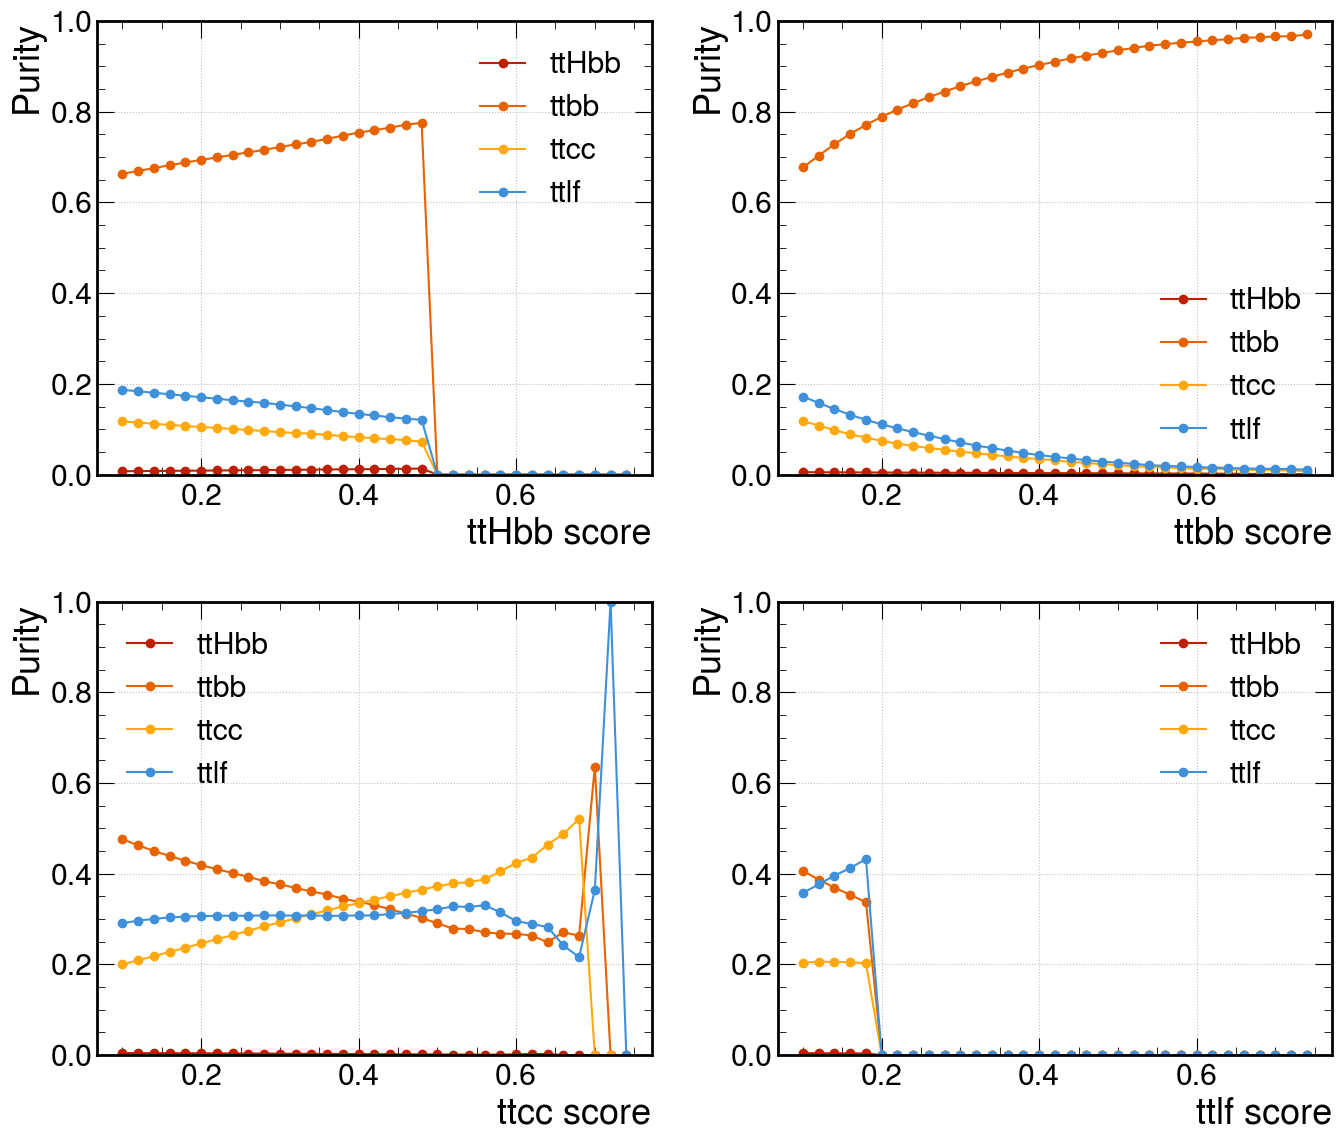

In [60]:
thr_vals = np.array(score_thr)

scores_to_plot = list(labels_to_plot.keys())   # or your score list
n_scores = len(scores_to_plot)

fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([purity[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Purity")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

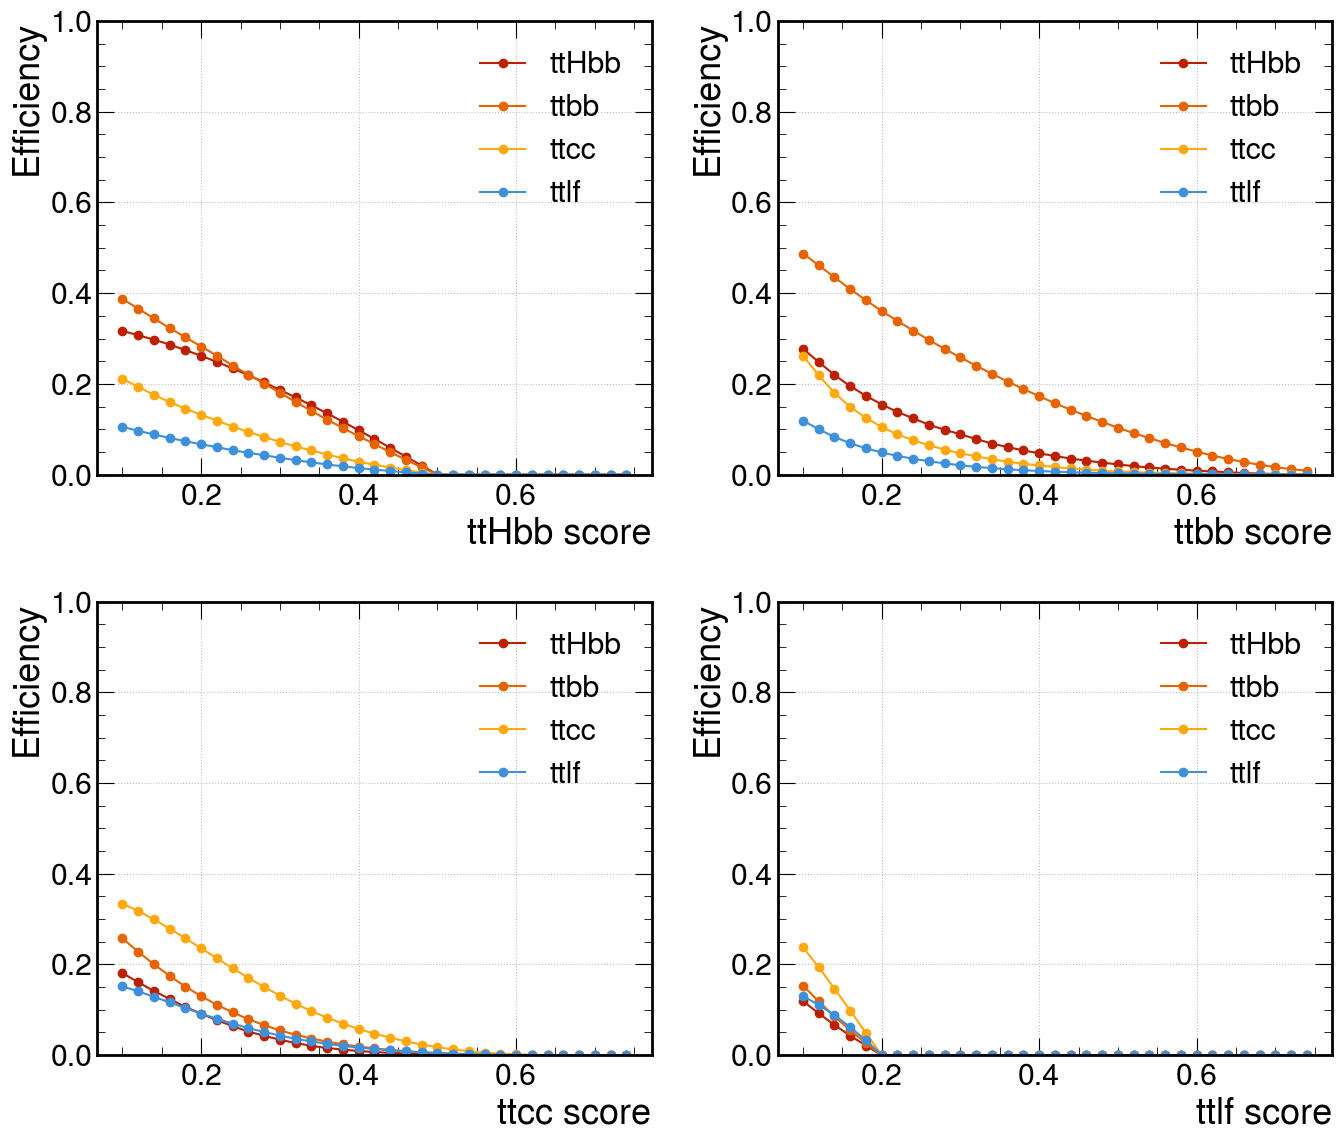

In [61]:
fig, axes = plt.subplots(2, 2,figsize=(14, 12))
axes = axes.flatten()
for ax, score in zip(axes, scores_to_plot):
    for sample in labels_to_plot.keys():
        pur_vals = np.array([efficiency[score][sample][thr] for thr in thr_vals])
        ax.plot(thr_vals,pur_vals,marker='o',linestyle='-',color=colors[sample],label=sample)

    ax.set_xlabel(f"{score} score")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

We can set the ttC control region around $ttcc\_score > 0.5$